# Food Recognition CNN: Colab Notebook (EfficientNet edition)

This notebook trains a CNN that recognises fruits, vegetables, dairy (milk and milk products) and other packaged food from a photo. It connects the datasets to the code, builds models, and compares them:

1. **Baseline CNN** built from scratch (kept for comparison in your report).
2. **EfficientNet transfer-learning model** (EfficientNetV2-B0 by default, pre-trained on ImageNet). This is the main model.

**What changed in this version**
- **Model:** MobileNetV2 was replaced by **EfficientNet** (choose the variant with `MODEL_NAME`). The training recipe was upgraded for accuracy: 224 px input, label smoothing, class weights, mixed precision, a two-stage fine-tune that keeps BatchNorm frozen, and flip test-time augmentation.
- **Disk space:** every download is checked against the free disk first. A dataset that does not fit is skipped (the log says why). Images are stored once, shrunk to a small size, and the raw download is deleted straight after.
- **Duplicates:** duplicate dataset sources are skipped, and duplicate images (exact, near-identical, and the same image under two labels) are removed **before** the train/validation/test split, so the test score is honest. Removed images are replaced with new unique ones where a source allows it.
- **More milk and product data:** Grocery Store dataset (milk, yoghurt, juice cartons), Freiburg Groceries, two Roboflow milk-packet sets, and a much wider Open Food Facts pull for milk, buttermilk, milk powder, condensed milk, ice cream and other products.

**Before you start**
1. Choose **Runtime > Change runtime type > T4 GPU**.
2. Run the cells from top to bottom. Cells marked **[COLAB]** only work inside Google Colab.
3. Use **Section 2B** to build the dataset (or one of the simple options A to C in Section 2).

**Expected folder layout** (class name = folder name):

```
dataset/
  train/        tomato/  onion/  potato/ ...
  validation/   tomato/  onion/  potato/ ...   (optional)
  test/         tomato/  onion/  potato/ ...   (optional)
```

A single folder of class folders also works. The notebook then makes its own 70/15/15 split.


## 1. Setup

In [ ]:
# [COLAB] Install anything Colab might be missing (usually nothing is needed)
!pip install -q scikit-learn pillow kagglehub huggingface_hub datasets

In [ ]:
import os, json, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

print("TensorFlow:", tf.__version__)
GPUS = tf.config.list_physical_devices("GPU")
print("GPU found:", GPUS)

TensorFlow: 2.21.0
GPU found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ---- Settings you can change ----
SEED = 42

# Main model. All of these are pre-trained on ImageNet.
#   "EfficientNetV2B0"  recommended: best accuracy for its size, trains fast on a T4
#   "EfficientNetB0"    older and a little faster
#   "EfficientNetV2S"   more accurate but about 3x slower. Use IMG_SIZE = (300, 300) and BATCH_SIZE = 16
#   "MobileNetV2"       the previous model, kept so you can show a comparison in your report
MODEL_NAME = "EfficientNetV2B0"
IMG_SIZE = (224, 224)       # EfficientNet-B0 family is designed for 224. Bigger = slower, often a little better
BATCH_SIZE = 32
EPOCHS_BASELINE = 20        # baseline CNN
EPOCHS_TRANSFER = 8         # stage 1: only the new top layers learn
EPOCHS_FINETUNE = 25        # stage 2: top part of EfficientNet learns too (early stopping ends it sooner)
MAX_PER_CLASS = 400         # use at most this many images per class. None = use all
WEIGHTS = "imagenet"

LABEL_SMOOTHING = 0.1       # stops the model being over-confident on noisy web photos
FINETUNE_FRACTION = 0.4     # share of the EfficientNet layers (from the top) that are unfrozen in stage 2
USE_CLASS_WEIGHTS = True    # gives rarer classes more weight when counts are uneven
USE_MIXED_PRECISION = True  # float16 maths on the GPU: faster, less memory (ignored on CPU)
TRAIN_BASELINE = True       # also train the from-scratch CNN for the comparison table
USE_TTA = True              # test-time augmentation: average the prediction of the photo and its mirror image
CONFIDENCE_THRESHOLD = 0.50 # below this the app should say "not sure, please confirm"

DATA_ROOT = "/content/data"  # where the dataset is stored (changed in Section 2 if you use Drive)

keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

if USE_MIXED_PRECISION and GPUS:
    keras.mixed_precision.set_global_policy("mixed_float16")
print("Compute policy:", keras.mixed_precision.global_policy().name)

Compute policy: mixed_float16


## 2. Connect the dataset

Pick **one** option and run only that option.

| Option | Use when |
|---|---|
| **A. Kaggle** | You want a public dataset quickly |
| **B. Google Drive** | Your dataset (or your own photos) is already in Drive |
| **C. Upload a zip** | Small dataset, quick test |

**Option A needs a Kaggle API key:** on kaggle.com go to *Settings > API > Create New Token*. This downloads a file called `kaggle.json`. You will upload it below.

Two datasets that work well:
- `kritikseth/fruit-and-vegetable-image-recognition` (36 classes, real-world style photos)
- `moltean/fruits` (Fruits-360, clean photos on white background)

If a download fails, open the dataset page on Kaggle and copy the part of the URL after `kaggle.com/datasets/`.

In [ ]:
# [COLAB] OPTION A: download from Kaggle
from google.colab import files
print("Choose your kaggle.json file")
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

KAGGLE_DATASET = "kritikseth/fruit-and-vegetable-image-recognition"
!kaggle datasets download -d $KAGGLE_DATASET -p /content/data --unzip -q
DATA_ROOT = "/content/data"

Choose your kaggle.json file


Saving kaggle.json to kaggle (1).json
Dataset URL: https://www.kaggle.com/datasets/kritikseth/fruit-and-vegetable-image-recognition
License(s): CC0-1.0


In [ ]:
# [COLAB] OPTION B: use a dataset stored in Google Drive
from google.colab import drive
drive.mount("/content/drive")

# Change this to the folder in your Drive that contains the class folders (or train/test folders)
DATA_ROOT = "/content/drive/MyDrive/food_dataset"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# @title
# [COLAB] OPTION C: upload a zip file from your computer
from google.colab import files
import zipfile
uploaded = files.upload()          # choose your .zip file
for name in uploaded:
    with zipfile.ZipFile(name) as z:
        z.extractall("/content/data")
DATA_ROOT = "/content/data"

## 2B. Build the dataset for all categories (alternative to Options A to C)

Use this section when you want the **full taxonomy** (now 18 categories, 147 items, with extra milk and dairy items). It downloads datasets, maps their classes onto **your** item names, and builds one folder:

```
/content/data/<item>/image files      (one folder per item, e.g. tomato, milk, soy_sauce)
/content/class_to_category.csv        (item -> category)
/content/space_report.csv             (how much disk every item and source uses)
```

**How the section works, in order**

| Step | What it does |
|---|---|
| 1. Disk check | Reads the free space and sets a budget: free space minus `DISK_RESERVE_GB` (kept free for training and checkpoints). Optional hard cap: `MAX_DATA_GB`. |
| 2. Admit or skip | Before each download the notebook finds the dataset size (asks Kaggle, Hugging Face or GitHub; reads the zip size for manual files; otherwise uses a safe estimate). A dataset that does not fit in the budget is **skipped and logged**, and the next one is tried. Sources run in priority order, so the ones that fill your gaps (milk, packaged items, Indian foods) come first and the big redundant ones come last. |
| 3. Store small | Each image is shrunk once (longest side about 1.15 x `IMG_SIZE`) and saved as JPEG. The raw download is then deleted, so the peak disk use is the largest single dataset, not the sum. |
| 4. Clean and de-duplicate | Removes unreadable and tiny files, exact copies, near-identical images inside a class, and any image that appears under two different labels. |
| 5. Replace | Items that fell below `TARGET_PER_ITEM` after de-duplication are topped up with new, unseen Open Food Facts photos, then checked again. |
| 6. Coverage and space reports | OK / LOW / MISSING per item, plus the disk used per item and per source. |

| Method | What it does | Needs |
|---|---|---|
| `kaggle` / `kagglehub` | Downloads a Kaggle dataset | Your `kaggle.json` (uploaded once) |
| `hf` | Downloads only the needed class folders from Hugging Face | Nothing |
| `git` | Clones a GitHub repository | Nothing |
| `manual` | Reads a `.zip`, `.tar.gz` or folder you downloaded in your browser (Mendeley, Roboflow, Freiburg) | Put `<id>.zip` (or `<id>.tar.gz`) in your Drive folder `food_datasets_manual` |
| `off` | Product photos from the Open Food Facts API | Nothing (small caps, delays) |

**Be aware**
- **No dataset covers every item.** Items with no image source (raw chicken, beef, pork, kale, millet) show as **MISSING**. Add your own phone photos under `/content/data/<item>/`.
- Open Food Facts and the Roboflow sets give **packaging photos**. Those classes learn the look of a pack or bottle, not the product inside.
- A classifier can say "milk", but not the brand or the nutrition facts. For branded products, scan the **barcode** and look the product up in Open Food Facts.
- Kaggle slugs marked `verified=False` were not confirmed. If one fails, search its name on Kaggle and fix `ref`.
- Check every dataset's licence before you use it. Roboflow sets listed here are CC BY 4.0 (credit the authors).


In [ ]:
import re, shutil, subprocess, zipfile, tarfile, time, csv
import requests
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# ---- Settings for the fetch ----
OUT_DIR = "/content/data"                                  # unified output (one folder per item)
RAW_DIR = "/content/raw"                                   # raw downloads (deleted after each source is stored)
MANUAL_DIR = "/content/drive/MyDrive/food_datasets_manual" # put manual zips here (named <id>.zip or <id>.tar.gz)
MAX_PER_SOURCE_ITEM = 300     # max images taken from one source for one item
OFF_MAX_PER_ITEM = 200        # max Open Food Facts photos per item (some items get more, see OFF_CAP_OVERRIDE)
MIN_IMAGES_PER_CLASS = 30     # items with fewer images are moved aside (too few to train on)
TARGET_PER_ITEM = 200         # after de-duplication, items below this are topped up where a source allows it
OFF_CONTACT = "your-email@example.com"   # Open Food Facts asks for a contact in the User-Agent. Put yours.
FETCH_ENABLED = {"kaggle": True, "kagglehub": True, "hf": True, "git": True, "git_extra": False, "manual": True, "off": True, "food101": False}
# git_extra = the extra Fruits-360 GitHub repositories (large). Turn on only if you need them.
# food101 streams a ~5 GB dataset (slow). Turn it on only if you need soup, salad and pasta dish photos.

# ---- Disk-space rules ----
DISK_RESERVE_GB = 6           # always keep this much free (model checkpoints, TensorFlow cache, Drive copies)
MAX_DATA_GB = None            # optional hard cap for the cleaned dataset folder, e.g. 3.0. None = only the free-space rule
DOWNLOAD_OVERHEAD = 2.0       # a zip and its unzipped copy exist together for a while, so a download needs about 2x its size
DELETE_RAW_AFTER_INGEST = True  # delete the raw download once its images are stored (strongly recommended)
STORE_MAX_SIDE = int(max(IMG_SIZE) * 1.15)   # images are stored with their longest side at most this many pixels
MIN_SIDE = 32                 # images with a shorter side than this are deleted as useless

# ---- Duplicate rules ----
NEAR_DUP_THRESHOLD = 4        # 0 = exact copies only. 4 = also near-identical images (resized, re-compressed, tiny edits). Max 7.

# ---- Your target taxonomy: category -> items ----
TAXONOMY = {
    "Fruits": ["apple", "banana", "mango", "orange", "grape", "watermelon", "pineapple", "papaya", "guava", "avocado", "lemon", "lime", "strawberry", "pomegranate"],
    "Vegetables": ["tomato", "potato", "onion", "carrot", "cucumber", "cabbage", "cauliflower", "eggplant", "capsicum", "beetroot", "pumpkin", "zucchini"],
    "Leafy greens and fresh herbs": ["spinach", "lettuce", "kale", "coriander leaves", "mint", "curry leaves", "fenugreek leaves"],
    "Grains and cereals": ["rice", "wheat", "oats", "corn", "barley", "millet", "ragi", "quinoa"],
    "Pulses, beans and lentils": ["chickpeas", "green gram", "black gram", "kidney beans", "lentils", "peas", "pigeon peas", "soybeans"],
    "Nuts and seeds": ["almonds", "cashews", "peanuts", "walnuts", "pistachios", "sesame", "chia", "flaxseed", "sunflower seeds"],
    "Dairy products": ["milk", "curd", "yoghurt", "cheese", "paneer", "butter", "ghee", "cream", "buttermilk", "milk powder", "condensed milk", "ice cream"],
    "Milk alternatives": ["soy milk", "almond milk", "oat milk", "coconut milk"],
    "Eggs and animal proteins": ["eggs", "chicken", "beef", "mutton", "pork", "tofu", "tempeh"],
    "Fish and seafood": ["sardines", "tuna", "salmon", "mackerel", "anchovies", "prawns", "crab", "mussels"],
    "Oils and fats": ["coconut oil", "sunflower oil", "olive oil", "groundnut oil", "mustard oil", "sesame oil"],
    "Spices and seasonings": ["turmeric", "chilli powder", "black pepper", "cumin", "coriander seeds", "cinnamon", "cardamom", "cloves", "garam masala"],
    "Sweeteners and baking ingredients": ["sugar", "jaggery", "honey", "flour", "baking powder", "cocoa powder", "yeast"],
    "Sauces and condiments": ["ketchup", "mayonnaise", "mustard", "soy sauce", "vinegar", "chutney", "pickles"],
    "Packaged staple foods": ["rice packets", "flour bags", "packaged oats", "pasta", "noodles", "bread", "breakfast cereals"],
    "Packaged snacks and convenience foods": ["biscuits", "chips", "crackers", "instant noodles", "frozen foods", "ready-to-eat meals"],
    "Beverages": ["water", "fruit juice", "soft drinks", "tea", "coffee", "packaged milk drinks"],
    "Prepared meals and dishes": ["biryani", "dosa", "idli", "chapati", "dal", "curry", "sambar", "salad", "soup", "pasta dishes"],
}
# (Ghee also belongs under Oils and fats. It is kept once, under Dairy products.)

# Extra names that should map to an item (matched against the dataset's own folder names)
EXTRA_ALIASES = {
    "capsicum": ["bell pepper", "paprika", "pepper"], "eggplant": ["aubergine", "brinjal"], "zucchini": ["courgette"],
    "grape": ["grapes"], "tomato": ["tomatoes"], "potato": ["potatoes"],
    "coriander leaves": ["coriander", "cilantro", "coriander leaf"], "curry leaves": ["curry leaf", "curry tree", "curry", "murraya", "bergera koenigii"],
    "fenugreek leaves": ["fenugreek", "methi", "trigonella"], "mint": ["mentha", "pudina"], "lettuce": ["salad leaf"],
    "corn": ["sweetcorn", "maize"], "rice": ["basmati", "jasmine", "arborio"],
    "chickpeas": ["chickpea", "chana", "kabuli", "chole"], "green gram": ["mung", "moong", "mugh", "mug", "whole green gram"],
    "black gram": ["urad", "mashkalai", "mash"], "kidney beans": ["rajma", "kidney bean", "red beans"], "lentils": ["lentil", "masoor", "masur"],
    "pigeon peas": ["pigeon pea", "orhor", "arhar", "toor", "tur"], "peas": ["pea", "motor", "green peas"],
    "soybeans": ["soy beans", "soya beans", "soya bean", "soyabean", "soy bean"],
    "almonds": ["almond"], "cashews": ["cashew", "cashew nut"], "peanuts": ["peanut", "groundnut"], "walnuts": ["walnut"], "pistachios": ["pistachio"],
    "yoghurt": ["yogurt", "yoghurts", "yogurts"], "curd": ["dahi", "curds"], "eggs": ["egg"],
    "soy milk": ["soya milk", "soy drink"], "oat milk": ["oat drink", "oatly"], "almond milk": ["almond drink"], "coconut milk": ["coconut drink"],
    "prawns": ["shrimp", "shrimps", "prawn"], "mackerel": ["mackerels"], "sardines": ["sardine"], "mussels": ["mussel"],
    "chilli powder": ["chili powder", "red chilli powder"], "black pepper": ["peppercorn"], "cumin": ["jeera", "cumin seeds"],
    "coriander seeds": ["coriander", "dhania", "coriander seed"], "cloves": ["clove"], "turmeric": ["haldi"],
    "fruit juice": ["juice", "juices"], "soft drinks": ["soda", "cola", "soft drink"], "water": ["mineral water"],
    "chapati": ["roti", "chappati", "phulka"], "dal": ["daal", "dhal"], "pasta dishes": ["spaghetti", "lasagna", "macaroni", "ravioli"],
}

# Source catalog. kind: kaggle / hf / git / manual.  mode: match (map by name) / explicit (map table) / fixed (everything -> one item)
CATALOG = [
    dict(id="fruits360", kind="kaggle", ref="moltean/fruits", verified=True, mode="match",
         cats=["Fruits", "Vegetables"], link="https://www.kaggle.com/datasets/moltean/fruits"),
    dict(id="fv36", kind="kaggle", ref="kritikseth/fruit-and-vegetable-image-recognition", verified=True, mode="match",
         cats=["Fruits", "Vegetables", "Leafy greens and fresh herbs", "Pulses, beans and lentils", "Grains and cereals", "Spices and seasonings"],
         link="https://hyper.ai/en/datasets/32609"),
    dict(id="nuts11", kind="kaggle", ref="ruopengan/11-common-nut-types-for-image-classification", verified=True, mode="match",
         cats=["Nuts and seeds"], link="https://www.kaggle.com/datasets/ruopengan/11-common-nut-types-for-image-classification"),
    dict(id="rice5", kind="kaggle", ref="muratkokludataset/rice-image-dataset", verified=False, mode="fixed", item="rice",
         link="https://www.muratkoklu.com/datasets/"),
    dict(id="fish9", kind="kaggle", ref="crowww/a-large-scale-fish-dataset", verified=False, mode="explicit",
         map={"shrimp": "prawns", "horse_mackerel": "mackerel"}, exclude=r"(^|_)gt$",
         link="https://ml.paperswithcode.com/dataset/a-large-scale-fish-dataset"),
    dict(id="indianfood_kaggle", kind="kaggle", ref="l33tc0d3r/indian-food-classification", verified=True, mode="explicit",
         map={"chapati": "chapati", "dal_makhani": "dal", "idli": "idli", "masala_dosa": "dosa", "kadai_paneer": "curry"},
         link="https://www.kaggle.com/datasets/l33tc0d3r/indian-food-classification"),
    dict(id="indianfood_hf", kind="hf", ref="SKSKCulinaryAI/Indian_Food_Images_Dataset", verified=True, mode="explicit",
         patterns=["train/Biryani/*", "train/Chappati/*", "train/Dosa/*", "train/Idli/*", "train/Dal makhani/*", "train/Toor dal/*", "train/Butter chicken/*", "train/Kadai_paneer/*"],
         map={"biryani": "biryani", "chappati": "chapati", "dosa": "dosa", "idli": "idli", "dal_makhani": "dal", "toor_dal": "dal", "butter_chicken": "curry", "kadai_paneer": "curry"},
         link="https://huggingface.co/datasets/SKSKCulinaryAI/Indian_Food_Images_Dataset"),
    # ---- your own Kaggle list (downloaded with kagglehub) ----
    dict(id="fruits_shreya", kind="kagglehub", ref="shreyapmaher/fruits-dataset-images", verified=True, mode="match",
         cats=["Fruits", "Vegetables"], link="https://www.kaggle.com/datasets/shreyapmaher/fruits-dataset-images"),
    dict(id="rotten_fv", kind="kagglehub", ref="muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten", verified=True, mode="match",
         cats=["Fruits", "Vegetables"], exclude=r"(^|_)(rotten|stale|spoiled|bad|disease|diseased|unhealthy)(_|$)",
         link="https://www.kaggle.com/datasets/muhammad0subhan/fruit-and-vegetable-disease-healthy-vs-rotten"),
    dict(id="fruits262", kind="kagglehub", ref="aelchimminut/fruits262", verified=True, mode="match",
         cats=["Fruits"], link="https://www.kaggle.com/datasets/aelchimminut/fruits262"),
    dict(id="packed_fv", kind="kagglehub", ref="sergeynesteruk/packed-fruits-and-vegetables-recognition-benchmark", verified=True, mode="match",
         cats=["Fruits", "Vegetables"], link="https://www.kaggle.com/datasets/sergeynesteruk/packed-fruits-and-vegetables-recognition-benchmark"),
    dict(id="food11", kind="kagglehub", ref="imbikramsaha/food11", verified=True, mode="explicit",
         map={"egg": "eggs", "soup": "soup", "noodles_pasta": "pasta dishes", "bread": "bread"},
         link="https://www.kaggle.com/datasets/imbikramsaha/food11"),
    dict(id="foodies_ai", kind="kagglehub", ref="jvageesh11/foodies-ai-food-image-classification-challenge", verified=True, mode="match",
         cats=["Prepared meals and dishes"], link="https://www.kaggle.com/datasets/jvageesh11/foodies-ai-food-image-classification-challenge"),
    # ---- your Fruits-360 GitHub repositories (off by default: large) ----
    dict(id="f360_100", kind="git_extra", ref="https://github.com/fruits-360/fruits-360-100x100.git", verified=True, mode="match",
         cats=["Fruits", "Vegetables"], link="https://github.com/fruits-360/fruits-360-100x100"),
    dict(id="f360_multi", kind="git_extra", ref="https://github.com/fruits-360/fruits-360-multi.git", verified=True, download_only=True,
         link="https://github.com/fruits-360/fruits-360-multi"),
    dict(id="f360_original", kind="git_extra", ref="https://github.com/fruits-360/fruits-360-original-size.git", verified=True, download_only=True,
         link="https://github.com/fruits-360/fruits-360-original-size"),
    dict(id="f360_3body", kind="git_extra", ref="https://github.com/fruits-360/fruits-360-3-body-problem.git", verified=True, download_only=True,
         link="https://github.com/fruits-360/fruits-360-3-body-problem"),
    dict(id="grocery", kind="git", ref="https://github.com/marcusklasson/GroceryStoreDataset.git", verified=False, mode="match",
         cats=["Fruits", "Vegetables", "Dairy products", "Milk alternatives", "Beverages"],
         link="https://github.com/marcusklasson/GroceryStoreDatasetPaper"),
    # ---- manual: download the zip in your browser, save it as <id>.zip in MANUAL_DIR ----
    dict(id="indian_lentils", kind="manual", mode="match", cats=["Pulses, beans and lentils"], link="https://data.mendeley.com/datasets/r4yhfnzc5y/1"),
    dict(id="bdlentil", kind="manual", mode="match", cats=["Pulses, beans and lentils"], link="https://data.mendeley.com/datasets/ksxcmtwbhy"),
    dict(id="dryfruit", kind="manual", mode="match", cats=["Nuts and seeds"], link="https://data.mendeley.com/datasets/yfhgn8py5f"),
    dict(id="allernuts", kind="manual", mode="match", cats=["Nuts and seeds"], link="https://data.mendeley.com/datasets/3gtbxvgm5f"),
    dict(id="spice_spectrum", kind="manual", mode="match", cats=["Spices and seasonings"], link="https://doi.org/10.17632/5v7w2hx8n5.2"),
    dict(id="spice_visual", kind="manual", mode="match", cats=["Spices and seasonings"], link="https://data.mendeley.com/datasets/h9pphm522g"),
    dict(id="spice_indian", kind="manual", mode="match", cats=["Spices and seasonings"], link="https://www.ncbi.nlm.nih.gov/pmc/articles/PMC11827071/"),
    dict(id="leaf_medicinal", kind="manual", mode="match", cats=["Leafy greens and fresh herbs"], link="https://data.mendeley.com/datasets/k8m93ft9kk/2"),
    dict(id="leaf_bd", kind="manual", mode="match", cats=["Leafy greens and fresh herbs"], link="https://data.mendeley.com/datasets/fj93rrfv2y/2"),
    dict(id="herb_species", kind="manual", mode="match", cats=["Leafy greens and fresh herbs"], link="https://data.mendeley.com/datasets/fmpf798zcn"),
    dict(id="rice_aruzz", kind="manual", mode="fixed", item="rice", link="https://data.mendeley.com/datasets/3mn9843tz2/3"),
    dict(id="khana", kind="manual", mode="match", cats=["Prepared meals and dishes"], link="https://khana.omkar.xyz"),
]

# Items filled from Open Food Facts (packaged products). Each list = category names to try, in order.
OFF_QUERIES = {
    "milk": ["Milks"], "curd": ["Curd", "Curds", "Dahi"], "yoghurt": ["Yogurts", "Yoghurts"], "cheese": ["Cheeses"], "paneer": ["Paneer"],
    "butter": ["Butters"], "ghee": ["Ghee", "Clarified butters"], "cream": ["Creams"],
    "soy milk": ["Soy milks", "Soy drinks"], "almond milk": ["Almond milks", "Almond drinks"], "oat milk": ["Oat milks", "Oat drinks"], "coconut milk": ["Coconut milks"],
    "eggs": ["Eggs"], "tofu": ["Tofu"], "tempeh": ["Tempeh"],
    "sardines": ["Sardines"], "tuna": ["Tunas", "Tuna"], "salmon": ["Salmons"], "mackerel": ["Mackerels"], "anchovies": ["Anchovies"],
    "prawns": ["Shrimps", "Prawns"], "crab": ["Crabs"], "mussels": ["Mussels"],
    "coconut oil": ["Coconut oils"], "sunflower oil": ["Sunflower oils"], "olive oil": ["Olive oils"], "groundnut oil": ["Groundnut oils", "Peanut oils"],
    "mustard oil": ["Mustard oils"], "sesame oil": ["Sesame oils"],
    "sesame": ["Sesame seeds"], "chia": ["Chia seeds"], "flaxseed": ["Flax seeds", "Flaxseeds"], "sunflower seeds": ["Sunflower seeds"],
    "oats": ["Rolled oats", "Oat flakes"], "barley": ["Barley"], "millet": ["Millets"], "ragi": ["Ragi", "Finger millet"], "quinoa": ["Quinoa"], "wheat": ["Wheat"],
    "chilli powder": ["Chili powders", "Chilli powder"], "garam masala": ["Garam masala"],
    "sugar": ["Sugars"], "jaggery": ["Jaggery"], "honey": ["Honeys"], "flour": ["Wheat flours", "Flours"], "baking powder": ["Baking powders"],
    "cocoa powder": ["Cocoa powders", "Cocoa"], "yeast": ["Yeasts", "Yeast"],
    "ketchup": ["Ketchup", "Tomato ketchup"], "mayonnaise": ["Mayonnaises"], "mustard": ["Mustards"], "soy sauce": ["Soy sauces"],
    "vinegar": ["Vinegars"], "chutney": ["Chutneys"], "pickles": ["Pickles"],
    "rice packets": ["Rices", "Basmati rices"], "flour bags": ["Wheat flours"], "packaged oats": ["Rolled oats"], "pasta": ["Pastas"],
    "noodles": ["Noodles"], "bread": ["Breads"], "breakfast cereals": ["Breakfast cereals"],
    "biscuits": ["Biscuits"], "chips": ["Chips and fries", "Crisps"], "crackers": ["Crackers"], "instant noodles": ["Instant noodles"],
    "frozen foods": ["Frozen foods"], "ready-to-eat meals": ["Meals", "Prepared meals"],
    "water": ["Waters"], "fruit juice": ["Fruit juices"], "soft drinks": ["Sodas", "Carbonated drinks"], "tea": ["Teas"], "coffee": ["Coffees"],
    "packaged milk drinks": ["Flavoured milks", "Milk drinks"],
}


# =====================================================================
# Additions in this version: more milk and product sources, duplicate sources, size estimates, priorities
# =====================================================================

# Extra aliases for the new dairy items
EXTRA_ALIASES.update({
    "buttermilk": ["chaas", "chaach", "lassi", "butter milk"],
    "condensed milk": ["condensed", "sweetened condensed milk"],
    "milk powder": ["powdered milk", "milk powders", "dried milk", "milk powder"],
    "ice cream": ["icecream", "ice-cream", "gelato"],
})

# Some sources hold the same pictures as another one. Mark them so they are not downloaded twice.
for _s in CATALOG:
    if _s["id"] == "f360_100":
        _s["duplicate_of"] = "fruits360"      # the GitHub 100x100 repo is the same Fruits-360 data as moltean/fruits on Kaggle

# New sources. Milk first.
CATALOG += [
    # Grocery Store Dataset (already listed above) holds milk, yoghurt and juice cartons photographed in shops. It is the best real-photo milk source here.
    # Freiburg Groceries: 25 classes of real shop and home photos (milk, juice, oil, sugar, flour, honey, tea, coffee, vinegar, pasta, rice, water, soda ...).
    # Main file freiburg_groceries_dataset.tar.gz is about 716 MB. Download it in your browser and save it as freiburg.tar.gz in MANUAL_DIR.
    dict(id="freiburg", kind="manual", mode="explicit", verified=True,
         map={"milk": "milk", "juice": "fruit juice", "sugar": "sugar", "flour": "flour", "honey": "honey", "tea": "tea", "coffee": "coffee",
              "vinegar": "vinegar", "pasta": "pasta", "rice": "rice packets", "water": "water", "soda": "soft drinks"},
         link="http://aisdatasets.informatik.uni-freiburg.de/freiburg_groceries/"),
    # Roboflow Universe milk-packet sets (CC BY 4.0). On the dataset page choose Download Dataset, any image format, and save the zip as <id>.zip in MANUAL_DIR.
    # They are detection sets (boxes are ignored), every image is used as a "milk" photo.
    dict(id="rf_milk_packet", kind="manual", mode="fixed", item="milk", verified=True,
         link="https://universe.roboflow.com/nano-cktse/milk_packet_detection"),
    dict(id="rf_milk_carton", kind="manual", mode="fixed", item="milk", verified=True,
         link="https://universe.roboflow.com/detection-tsatn/milk_carton"),
]

# Rough sizes in MB, used only when the real size cannot be read before downloading. They are deliberately on the high side.
EST_MB = {
    "fruits360": 1500, "fv36": 2200, "nuts11": 800, "rice5": 300, "fish9": 4000, "indianfood_kaggle": 600, "indianfood_hf": 400,
    "fruits_shreya": 500, "rotten_fv": 2500, "fruits262": 12000, "packed_fv": 2000, "food11": 1200, "foodies_ai": 1500,
    "f360_100": 1500, "f360_multi": 3000, "f360_original": 3000, "f360_3body": 3000, "grocery": 1500,
    "freiburg": 716, "rf_milk_packet": 150, "rf_milk_carton": 150,
}
DEFAULT_EST_MB = 1000

# Lower number = fetched earlier. Sources that fill gaps (milk, packaged items, Indian foods) first, big redundant ones last.
PRIORITY = {
    "grocery": 1, "freiburg": 1, "rf_milk_packet": 1, "rf_milk_carton": 1, "indianfood_hf": 1, "indianfood_kaggle": 1,
    "nuts11": 1, "rice5": 1, "fish9": 2, "indian_lentils": 1, "bdlentil": 1, "dryfruit": 1, "allernuts": 2, "spice_spectrum": 1,
    "spice_visual": 1, "spice_indian": 1, "leaf_medicinal": 1, "leaf_bd": 1, "herb_species": 1, "rice_aruzz": 2, "khana": 1,
    "fruits360": 2, "fv36": 2, "fruits_shreya": 2, "food11": 2,
    "rotten_fv": 3, "packed_fv": 3, "foodies_ai": 3, "fruits262": 4,
    "f360_100": 5, "f360_multi": 5, "f360_original": 5, "f360_3body": 5,
}

# Open Food Facts: new items and a wider milk pull. These items take photos from SEVERAL Open Food Facts categories (union, duplicates removed).
OFF_QUERIES.update({
    "milk": ["Milks", "Whole milks", "Semi-skimmed milks", "Skimmed milks", "UHT milks", "Fresh milks", "Pasteurized milks", "Lactose-free milks"],
    "buttermilk": ["Buttermilks", "Lassi"],
    "milk powder": ["Milk powders", "Powdered milks"],
    "condensed milk": ["Condensed milks", "Sweetened condensed milks"],
    "ice cream": ["Ice creams"],
    "packaged milk drinks": ["Flavoured milks", "Milk drinks", "Chocolate milks", "Milkshakes"],
    "yoghurt": ["Yogurts", "Yoghurts", "Plain yogurts"],
    "cheese": ["Cheeses", "Fresh cheeses"],
})
OFF_MULTI_LABEL = {"milk", "buttermilk", "milk powder", "condensed milk", "packaged milk drinks", "yoghurt", "cheese", "curd", "soy milk", "almond milk", "oat milk"}
OFF_CAP_OVERRIDE = {"milk": 400, "yoghurt": 250, "cheese": 250, "packaged milk drinks": 250}

print(sum(len(v) for v in TAXONOMY.values()), "items in", len(TAXONOMY), "categories;", len(CATALOG), "image sources")

147 items in 18 categories; 33 image sources


In [ ]:
def norm(s):
    return re.sub(r"[^a-z0-9]+", "_", str(s).lower()).strip("_")

def _sing(tok):
    return tok[:-1] if len(tok) > 3 and tok.endswith("s") and not tok.endswith("ss") else tok

def toks(s):
    return [_sing(t) for t in norm(s).split("_") if t]

def _find_end(name_toks, alias_toks):
    """Index of the last token of the LAST place where alias_toks appears in name_toks, or -1."""
    n = len(alias_toks)
    ends = [i + n - 1 for i in range(len(name_toks) - n + 1) if n > 0 and name_toks[i:i + n] == alias_toks]
    return ends[-1] if ends else -1

ITEM_ALIASES = {}
for _cat, _items in TAXONOMY.items():
    for _it in _items:
        ITEM_ALIASES[_it] = [_it] + EXTRA_ALIASES.get(_it, [])
ITEM_CATEGORY = {}
for _cat, _items in TAXONOMY.items():
    for _it in _items:
        ITEM_CATEGORY.setdefault(_it, _cat)


def match_item(class_name, cats):
    """Map a dataset class name to one of OUR items.
    The match that ends last in the name wins (the main noun comes last: 'Apple Juice' -> juice),
    and a longer alias beats a shorter one ('soy milk' beats 'milk')."""
    name_t = toks(class_name)
    best = None
    for cat in cats:
        for item in TAXONOMY[cat]:
            for alias in ITEM_ALIASES[item]:
                at = toks(alias)
                end = _find_end(name_t, at)
                if end >= 0 and (best is None or (end, len(at)) > best[0]):
                    best = ((end, len(at)), item)
    return best[1] if best else None


def map_class(src, class_name):
    mode = src["mode"]
    if mode == "match":
        return match_item(class_name, src["cats"])
    if mode == "explicit":
        return src["map"].get(norm(class_name))
    if mode == "fixed":
        return src["item"]
    return None


# =====================================================================
# Disk-space tools
# =====================================================================
SIZE_LOG = []      # one row per source: what it was expected to need, what happened
REMOVED = set()    # "<item>/<file>" of images removed as duplicates, so a top-up never downloads them again


def disk_status(path=None):
    path = path or os.path.dirname(OUT_DIR.rstrip("/")) or "."
    os.makedirs(path, exist_ok=True)
    total, used, free = shutil.disk_usage(path)
    return dict(total_gb=total / 1e9, used_gb=used / 1e9, free_gb=free / 1e9)


def dir_size_mb(path):
    """Real size of a folder in MB. Symbolic links are not counted twice."""
    total = 0
    for root, _, files_ in os.walk(path):
        for f in files_:
            fp = os.path.join(root, f)
            try:
                if not os.path.islink(fp):
                    total += os.path.getsize(fp)
            except OSError:
                pass
    return total / 1e6


def free_budget_mb():
    """How many MB we may still use: free disk minus the reserve (and minus the optional cap on the cleaned dataset)."""
    budget = disk_status()["free_gb"] * 1000 - DISK_RESERVE_GB * 1000
    if MAX_DATA_GB is not None:
        budget = min(budget, MAX_DATA_GB * 1000 - dir_size_mb(OUT_DIR))
    return budget


def _kaggle_creds():
    p = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(p):
        d = json.load(open(p))
        return d.get("username"), d.get("key")
    return os.environ.get("KAGGLE_USERNAME"), os.environ.get("KAGGLE_KEY")


def probe_size_mb(src):
    """Best-effort download size in MB BEFORE downloading. Returns (mb, how) where how is 'probed', 'file' or 'estimate'."""
    kind = src["kind"]
    try:
        if kind == "manual":
            for ext in (".zip", ".tar.gz", ".tgz", ".tar"):
                p = os.path.join(MANUAL_DIR, src["id"] + ext)
                if os.path.exists(p):
                    return os.path.getsize(p) / 1e6, "file"
        elif kind == "hf":
            import fnmatch
            from huggingface_hub import HfApi
            info = HfApi().dataset_info(src["ref"], files_metadata=True)
            pats = src.get("patterns")
            tot = sum((s.size or 0) for s in info.siblings if not pats or any(fnmatch.fnmatch(s.rfilename, p) for p in pats))
            if tot > 0:
                return tot / 1e6, "probed"
        elif kind in ("git", "git_extra"):
            m = re.search(r"github\.com/([^/]+)/([^/.]+)", src["ref"])
            r = requests.get(f"https://api.github.com/repos/{m.group(1)}/{m.group(2)}", timeout=20)
            if r.status_code == 200 and r.json().get("size"):
                return r.json()["size"] / 1024, "probed"
        elif kind in ("kaggle", "kagglehub"):
            user, key = _kaggle_creds()
            if user and key:
                r = requests.get(f"https://www.kaggle.com/api/v1/datasets/view/{src['ref']}", auth=(user, key), timeout=20)
                if r.status_code == 200:
                    tb = r.json().get("totalBytes")
                    if tb:
                        return tb / 1e6, "probed"
    except Exception:
        pass
    return float(src.get("est_mb") or EST_MB.get(src["id"], DEFAULT_EST_MB)), "estimate"


def admit(src):
    """Decide whether a source fits. Returns (ok, needed_mb, how, available_mb)."""
    mb, how = probe_size_mb(src)
    factor = DOWNLOAD_OVERHEAD if src["kind"] in ("kaggle", "kagglehub") else 1.3
    need = mb * factor
    avail = free_budget_mb()
    return need <= avail, need, how, avail


def reclaim_raw(src, folder):
    """Delete the raw download after its images have been stored. Returns the MB freed."""
    if not DELETE_RAW_AFTER_INGEST or not folder or src.get("download_only"):
        return 0.0
    target = os.path.abspath(folder)
    if src["kind"] == "kagglehub":
        parts = target.split(os.sep)
        if "datasets" in parts:
            target = os.sep.join(parts[: parts.index("datasets") + 3])      # .../datasets/<owner>/<name>
    if not target.startswith(os.path.abspath(RAW_DIR) + os.sep):
        return 0.0                                                          # never delete anything outside RAW_DIR
    mb = dir_size_mb(target)
    shutil.rmtree(target, ignore_errors=True)
    return mb


# =====================================================================
# Store images small, once
# =====================================================================
def place(path, item, tag, k):
    """Put one image into OUT_DIR/<item>/ as a small JPEG. Returns True if it was stored."""
    from PIL import Image
    folder = os.path.join(OUT_DIR, norm(item))
    os.makedirs(folder, exist_ok=True)
    dst = os.path.join(folder, f"{tag}__{k:05d}.jpg")
    if os.path.exists(dst):
        return True
    try:
        with Image.open(path) as im:
            im = im.convert("RGB")
            if min(im.size) < MIN_SIDE:
                return False
            im.thumbnail((STORE_MAX_SIDE, STORE_MAX_SIDE))
            im.save(dst, "JPEG", quality=90)
        return True
    except Exception:
        if os.path.exists(dst):
            os.remove(dst)
        return False


def ingest_folder(src, folder):
    """Find every folder of images under `folder`, map its name to an item, and store the images."""
    per_class, parent_of = defaultdict(list), {}
    for root, _, files_ in os.walk(folder):
        imgs = [f for f in files_ if f.lower().endswith(IMG_EXT)]
        if imgs:
            leaf = os.path.basename(root)
            per_class[leaf] += [os.path.join(root, f) for f in imgs]
            parent_of[leaf] = os.path.basename(os.path.dirname(root))
    added, skipped, k = defaultdict(int), [], defaultdict(int)
    for cname in sorted(per_class):
        if src.get("exclude") and re.search(src["exclude"], norm(cname)):
            continue
        item = map_class(src, cname)
        if not item and src["mode"] == "match":
            item = map_class(src, parent_of[cname])        # e.g. Apple/Golden-Delicious: the leaf name says nothing, the parent folder does
        if not item:
            skipped.append(cname)
            continue
        paths = sorted(per_class[cname])
        random.Random(SEED).shuffle(paths)
        for p in paths:
            if added[item] >= MAX_PER_SOURCE_ITEM:
                break
            if place(p, item, src["id"], k[item]):
                added[item] += 1
            k[item] += 1
    return dict(added), skipped


# ---------- downloaders ----------
_kaggle_ready = None

def ensure_kaggle_auth():
    global _kaggle_ready
    if _kaggle_ready is not None:
        return _kaggle_ready
    p = os.path.expanduser("~/.kaggle/kaggle.json")
    if os.path.exists(p) or os.environ.get("KAGGLE_KEY"):
        _kaggle_ready = True
        return True
    try:
        from google.colab import files as colab_files
        print("Upload your kaggle.json (Kaggle > Settings > API > Create New Token)")
        up = colab_files.upload()
        os.makedirs(os.path.dirname(p), exist_ok=True)
        with open(p, "wb") as f:
            f.write(next(iter(up.values())))
        os.chmod(p, 0o600)
        _kaggle_ready = True
    except Exception as e:
        print("Kaggle login is not set up:", e)
        _kaggle_ready = False
    return _kaggle_ready


def fetch_kaggle(src):
    dest = os.path.join(RAW_DIR, src["id"])
    if os.path.isdir(dest) and os.listdir(dest):
        return dest
    if not ensure_kaggle_auth():
        raise RuntimeError("no Kaggle login")
    os.makedirs(dest, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", src["ref"], "-p", dest, "--unzip", "-q"], check=True)
    return dest


def fetch_hf(src):
    from huggingface_hub import snapshot_download
    dest = os.path.join(RAW_DIR, src["id"])
    snapshot_download(repo_id=src["ref"], repo_type="dataset", local_dir=dest, allow_patterns=src.get("patterns"))
    return dest


def fetch_git(src):
    dest = os.path.join(RAW_DIR, src["id"])
    if not os.path.isdir(dest):
        subprocess.run(["git", "clone", "--depth", "1", src["ref"], dest], check=True)
    return dest


def _safe_extract_tar(path, dest):
    with tarfile.open(path) as t:
        try:
            t.extractall(dest, filter="data")
        except TypeError:                      # older Python without extraction filters
            t.extractall(dest)


def fetch_manual(src):
    """Use <MANUAL_DIR>/<id>.zip, <id>.tar.gz (or an extracted folder). Returns None if it is not there."""
    dest = os.path.join(RAW_DIR, src["id"])
    if os.path.isdir(dest) and os.listdir(dest):
        return dest
    zip_path = os.path.join(MANUAL_DIR, src["id"] + ".zip")
    folder_path = os.path.join(MANUAL_DIR, src["id"])
    if os.path.exists(zip_path):
        os.makedirs(dest, exist_ok=True)
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest)
        return dest
    for ext in (".tar.gz", ".tgz", ".tar"):
        tp = os.path.join(MANUAL_DIR, src["id"] + ext)
        if os.path.exists(tp):
            os.makedirs(dest, exist_ok=True)
            _safe_extract_tar(tp, dest)
            return dest
    if os.path.isdir(folder_path):
        return folder_path
    return None


def fetch_kagglehub(src):
    """Download with kagglehub (the same call Kaggle shows on each dataset page). Returns the local folder."""
    os.environ.setdefault("KAGGLEHUB_CACHE", os.path.join(RAW_DIR, "kagglehub"))
    try:
        import kagglehub
    except ImportError:
        subprocess.run(["pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    if not ensure_kaggle_auth():
        raise RuntimeError("no Kaggle login")
    return kagglehub.dataset_download(src["ref"])


FETCHERS = {"kaggle": fetch_kaggle, "kagglehub": fetch_kagglehub, "hf": fetch_hf, "git": fetch_git,
            "git_extra": fetch_git, "manual": fetch_manual}


# ---------- Open Food Facts (packaged products) ----------
def _ua():
    return {"User-Agent": f"FoodRecognitionStudentProject/1.0 ({OFF_CONTACT})"}

def _get(url, **kw):
    for attempt in range(4):
        try:
            r = requests.get(url, headers=_ua(), timeout=60, **kw)
            if r.status_code == 200:
                return r
        except requests.RequestException:
            pass
        time.sleep(2 * (attempt + 1))      # Open Food Facts sometimes answers 503: wait and retry
    return None

_off_cats = None

def off_categories():
    global _off_cats
    if _off_cats is None:
        r = _get("https://world.openfoodfacts.org/categories.json")
        best = {}
        if r is not None:
            for t in r.json().get("tags", []):
                nm = str(t.get("name", "")).lower()
                if nm and (nm not in best or t.get("products", 0) > best[nm].get("products", 0)):
                    best[nm] = t
        _off_cats = best
    return _off_cats


def resolve_off_tag(labels):
    cats = off_categories()
    for lab in labels:                      # 1) exact name
        t = cats.get(lab.lower())
        if t:
            return t["id"]
    for lab in labels:                      # 2) name that contains the label as whole words (most products wins)
        pat = re.compile(r"\b" + re.escape(lab.lower()) + r"\b")
        hits = [t for nm, t in cats.items() if pat.search(nm)]
        if hits:
            return max(hits, key=lambda t: t.get("products", 0))["id"]
    return None


def fetch_off_item(item, labels, cap, max_pages=5, multi=None):
    """Download up to `cap` front-of-pack photos for one item.
    For milk-type items (OFF_MULTI_LABEL) photos come from several Open Food Facts categories (a union), which gives more variety."""
    multi = (item in OFF_MULTI_LABEL) if multi is None else multi
    tags = []
    if multi:
        for lab in labels:
            t = resolve_off_tag([lab])
            if t and t not in tags:
                tags.append(t)
    else:
        t = resolve_off_tag(labels)
        tags = [t] if t else []
    if not tags:
        return 0, None
    per_tag = max(1, -(-cap // len(tags)))
    found, seen = [], set()
    for tag in tags:
        got, page = 0, 1
        while got < per_tag and page <= max_pages:
            r = _get("https://world.openfoodfacts.org/api/v2/search",
                     params=dict(categories_tags=tag, fields="code,image_front_small_url,image_front_url", page_size=100, page=page))
            prods = r.json().get("products", []) if r is not None else []
            if not prods:
                break
            for p in prods:
                u = p.get("image_front_small_url") or p.get("image_front_url")
                code_ = p.get("code")
                if u and code_ and code_ not in seen:
                    seen.add(code_)
                    found.append((code_, u))
                    got += 1
            page += 1
            time.sleep(0.6)
    found = found[:cap]
    folder = os.path.join(OUT_DIR, norm(item))
    os.makedirs(folder, exist_ok=True)

    def download(cu):
        code_, url = cu
        name = f"off__{code_}.jpg"
        if f"{norm(item)}/{name}" in REMOVED:      # a duplicate we already removed: do not bring it back
            return 0
        dst = os.path.join(folder, name)
        if os.path.exists(dst):
            return 1
        r = _get(url)
        if r is None or not r.headers.get("content-type", "").startswith("image"):
            return 0
        with open(dst, "wb") as f:
            f.write(r.content)
        return 1

    with ThreadPoolExecutor(max_workers=6) as ex:
        n = sum(ex.map(download, found))
    return n, "+".join(t.replace("en:", "") for t in tags[:3]) + (" ..." if len(tags) > 3 else "")


# ---------- optional: Food-101 (soup, salad, pasta dishes) ----------
FOOD101_MAP = {"caesar_salad": "salad", "greek_salad": "salad", "caprese_salad": "salad", "beet_salad": "salad",
               "french_onion_soup": "soup", "miso_soup": "soup", "hot_and_sour_soup": "soup",
               "spaghetti_bolognese": "pasta dishes", "spaghetti_carbonara": "pasta dishes", "lasagna": "pasta dishes", "ravioli": "pasta dishes",
               "chicken_curry": "curry"}

def fetch_food101(cap):
    from datasets import load_dataset
    ds = load_dataset("ethz/food101", split="train", streaming=True)
    names = ds.features["label"].names
    counts = defaultdict(int)
    wanted = set(FOOD101_MAP.values())
    for ex in ds:
        item = FOOD101_MAP.get(names[ex["label"]])
        if not item or counts[item] >= cap:
            continue
        folder = os.path.join(OUT_DIR, norm(item))
        os.makedirs(folder, exist_ok=True)
        im = ex["image"].convert("RGB")
        im.thumbnail((STORE_MAX_SIDE, STORE_MAX_SIDE))
        im.save(os.path.join(folder, f"food101__{counts[item]:05d}.jpg"), quality=90)
        counts[item] += 1
        if all(counts[i] >= cap for i in wanted):
            break
    return dict(counts)


def run_fetch():
    os.makedirs(OUT_DIR, exist_ok=True)
    os.makedirs(RAW_DIR, exist_ok=True)
    s = disk_status()
    print(f"Disk: {s['free_gb']:.1f} GB free of {s['total_gb']:.1f} GB. Reserve {DISK_RESERVE_GB} GB -> usable budget {free_budget_mb()/1000:.1f} GB\n")
    problems = []
    for src in sorted(CATALOG, key=lambda x: PRIORITY.get(x["id"], 2)):
        kind = src["kind"]
        if not FETCH_ENABLED.get(kind, True):
            continue
        if src.get("duplicate_of"):
            print(f"[dup]    {src['id']}: same pictures as '{src['duplicate_of']}', not downloaded")
            SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=0, how="-", kept_mb=0, status=f"skipped: duplicate of {src['duplicate_of']}"))
            continue
        ok, need, how, avail = admit(src)
        if not ok:
            print(f"[budget] {src['id']}: needs about {need:,.0f} MB ({how}) but only {avail:,.0f} MB is available. Skipped.")
            SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=round(need), how=how, kept_mb=0, status="skipped: not enough disk space"))
            continue
        before = dir_size_mb(OUT_DIR)
        try:
            folder = FETCHERS[kind](src)
            if folder is None:
                print(f"[skip]   {src['id']}: file not found. Download from {src['link']} and save as {src['id']}.zip (or .tar.gz) in {MANUAL_DIR}")
                SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=round(need), how=how, kept_mb=0, status="skipped: manual file missing"))
                continue
            if src.get("download_only"):
                print(f"[ok]     {src['id']}: downloaded to {folder} (not mapped to items; kept for later, for example multi-item detection)")
                SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=round(need), how=how, kept_mb=0, status="downloaded (raw kept)"))
                continue
            raw_mb = dir_size_mb(folder)
            added, skipped = ingest_folder(src, folder)
            kept = dir_size_mb(OUT_DIR) - before
            freed = reclaim_raw(src, folder)
            warn = "" if src.get("verified", True) or kind not in ("kaggle", "kagglehub") else "  (slug not verified)"
            print(f"[ok]     {src['id']}: {sum(added.values())} images into {len(added)} items; raw {raw_mb:,.0f} MB -> kept {kept:,.0f} MB, freed {freed:,.0f} MB; {len(skipped)} folders not in your taxonomy{warn}")
            SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=round(need), how=how, kept_mb=round(kept), status="ok"))
        except Exception as e:
            problems.append(src["id"])
            print(f"[FAILED] {src['id']}: {e}  -> open {src['link']}")
            SIZE_LOG.append(dict(id=src["id"], kind=kind, need_mb=round(need), how=how, kept_mb=0, status=f"failed: {e}"[:120]))
    if FETCH_ENABLED.get("off", True):
        for item, labels in OFF_QUERIES.items():
            if free_budget_mb() < 100:
                print("[budget] Open Food Facts stopped: less than 100 MB of budget left")
                break
            try:
                cap = OFF_CAP_OVERRIDE.get(item, OFF_MAX_PER_ITEM)
                n, tag = fetch_off_item(item, labels, cap)
                print(f"[off]    {item}: {n} photos  ({tag})" if tag else f"[off]    {item}: category not found for {labels}")
            except Exception as e:
                problems.append("off:" + item)
                print(f"[FAILED] off {item}: {e}")
    if FETCH_ENABLED.get("food101", False):
        ok, need, how, avail = admit(dict(id="food101", kind="hf", ref="", est_mb=5000))
        if ok:
            print("[food101]", fetch_food101(MAX_PER_SOURCE_ITEM))
        else:
            print(f"[budget] food101: needs about {need:,.0f} MB but only {avail:,.0f} MB is available. Skipped.")
    return problems


def count_images(item):
    folder = os.path.join(OUT_DIR, norm(item))
    if not os.path.isdir(folder):
        return 0
    return sum(f.lower().endswith(IMG_EXT) for f in os.listdir(folder))


def coverage_report(move_low=True):
    """Print images per item, write class_to_category.csv, and move items with too few images aside."""
    low_dir = OUT_DIR + "_low"
    rows, ready = [], 0
    for cat, items in TAXONOMY.items():
        n_ready = 0
        print(f"\n{cat}")
        for it in items:
            n = count_images(it)
            status = "OK" if n >= MIN_IMAGES_PER_CLASS else ("LOW" if n > 0 else "MISSING")
            n_ready += status == "OK"
            print(f"   {it:22s} {n:5d}  {status}")
            rows.append((norm(it), cat, n, status))
            if move_low and status == "LOW":
                os.makedirs(low_dir, exist_ok=True)
                shutil.move(os.path.join(OUT_DIR, norm(it)), os.path.join(low_dir, norm(it)))
        ready += n_ready
        print(f"   -> {n_ready}/{len(items)} items ready")
    csv_path = os.path.join(os.path.dirname(OUT_DIR), "class_to_category.csv")
    os.makedirs(os.path.dirname(csv_path), exist_ok=True)
    with open(csv_path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["item", "category", "images", "status"])
        w.writerows(rows)
    total = sum(len(v) for v in TAXONOMY.values())
    print(f"\nReady to train: {ready}/{total} items. Add your own photos for the MISSING and LOW items.")
    print("Item -> category list saved to", csv_path)
    return rows

In [ ]:
# =====================================================================
# Clean and de-duplicate, then replace what was removed
# =====================================================================
def img_info(path):
    """Open the image (this also proves it is readable) and return (64-bit difference hash, shorter side)."""
    from PIL import Image
    with Image.open(path) as im:
        im.load()
        w, h = im.size
        g = im.convert("L").resize((9, 8), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    hv = 0
    for b in bits:
        hv = (hv << 1) | int(b)
    return hv, min(w, h)


def _bands(hv):
    return [(i, (hv >> (8 * i)) & 0xFF) for i in range(8)]       # 8 bands of 8 bits: two hashes <= 7 bits apart share at least one band


def clean_and_dedupe(near_threshold=None, verbose=True):
    """Remove (1) unreadable or tiny files, (2) the same image under two different labels (we cannot tell which label is right),
    (3) exact and near-identical images inside one class. Real photos are kept in preference to Open Food Facts packshots."""
    near_threshold = NEAR_DUP_THRESHOLD if near_threshold is None else near_threshold
    stats, removed_per_item = defaultdict(int), defaultdict(int)
    recs = []                                                      # (item, path, hash)
    for item in sorted(os.listdir(OUT_DIR)):
        d = os.path.join(OUT_DIR, item)
        if not os.path.isdir(d):
            continue
        files_ = sorted((f for f in os.listdir(d) if f.lower().endswith(IMG_EXT)), key=lambda f: (f.startswith("off__"), f))
        for f in files_:
            p = os.path.join(d, f)
            try:
                hv, ms = img_info(p)
            except Exception:
                os.remove(p); REMOVED.add(f"{item}/{f}"); stats["unreadable"] += 1; removed_per_item[item] += 1
                continue
            if ms < MIN_SIDE:
                os.remove(p); REMOVED.add(f"{item}/{f}"); stats["too_small"] += 1; removed_per_item[item] += 1
                continue
            recs.append((item, p, hv))
    stats["scanned_ok"] = len(recs)

    drop = {}
    by_hash = defaultdict(list)
    for r in recs:
        by_hash[r[2]].append(r)
    for grp in by_hash.values():                                   # same picture, different labels
        if len({g[0] for g in grp}) > 1:
            for g in grp:
                drop[g[1]] = "label_conflict"

    buckets = defaultdict(lambda: defaultdict(list))               # item -> (band, value) -> [hashes kept so far]
    for item, p, hv in recs:
        if p in drop:
            continue
        bk, dist = buckets[item], None
        for key in _bands(hv):
            for other in bk[key]:
                d = bin(hv ^ other).count("1")
                if d <= near_threshold and (dist is None or d < dist):
                    dist = d
        if dist is not None:
            drop[p] = "identical_picture" if dist == 0 else "near_duplicate"
        else:
            for key in _bands(hv):
                bk[key].append(hv)

    for p, why in drop.items():
        item, f = os.path.basename(os.path.dirname(p)), os.path.basename(p)
        try:
            os.remove(p)
        except OSError:
            continue
        REMOVED.add(f"{item}/{f}")
        stats[why] += 1
        removed_per_item[item] += 1
    for item in os.listdir(OUT_DIR):                               # remove folders that became empty
        d = os.path.join(OUT_DIR, item)
        if os.path.isdir(d) and not os.listdir(d):
            os.rmdir(d)
    if verbose:
        print("Clean-up and de-duplication")
        for k in ("scanned_ok", "unreadable", "too_small", "label_conflict", "identical_picture", "near_duplicate"):
            print(f"   {k:18s} {stats.get(k, 0):7d}")
        heavy = sorted(((n, i) for i, n in removed_per_item.items() if n >= 10), reverse=True)[:10]
        if heavy:
            print("   most removed:", ", ".join(f"{i} ({n})" for n, i in heavy))
    return dict(stats), dict(removed_per_item)


def top_up_after_dedupe(rounds=2):
    """Replace removed duplicates with NEW unique images. Works for every item that has an Open Food Facts query.
    For other items, add a new source to CATALOG or your own photos."""
    if not FETCH_ENABLED.get("off", True):
        print("Open Food Facts is switched off, so nothing can be topped up automatically.")
        return
    for rnd in range(1, rounds + 1):
        short = [it for it in OFF_QUERIES if count_images(it) < TARGET_PER_ITEM]
        if not short:
            print(f"Round {rnd}: every Open-Food-Facts item has at least {TARGET_PER_ITEM} images.")
            return
        print(f"Round {rnd}: topping up {len(short)} items below {TARGET_PER_ITEM} images")
        for item in short:
            if free_budget_mb() < 100:
                print("[budget] top-up stopped: less than 100 MB of budget left")
                return
            need = TARGET_PER_ITEM - count_images(item)
            try:
                n, tag = fetch_off_item(item, OFF_QUERIES[item], cap=OFF_CAP_OVERRIDE.get(item, OFF_MAX_PER_ITEM) + 4 * need, max_pages=15)
                print(f"   {item:22s} now {count_images(item):4d} images" if tag else f"   {item:22s} category not found")
            except Exception as e:
                print(f"   {item}: top-up failed: {e}")
        clean_and_dedupe(verbose=False)                            # the new photos can contain duplicates too
    print("Items still short after top-up:", [(it, count_images(it)) for it in OFF_QUERIES if count_images(it) < TARGET_PER_ITEM])


def space_report(save=True):
    """How much disk the dataset uses: totals, per item, per source, and how many more images fit."""
    s = disk_status()
    rows = []
    for item in sorted(os.listdir(OUT_DIR)):
        d = os.path.join(OUT_DIR, item)
        if os.path.isdir(d):
            rows.append((item, count_images(item), dir_size_mb(d)))
    total_mb = sum(r[2] for r in rows)
    n_img = sum(r[1] for r in rows)
    print(f"Disk: {s['used_gb']:.1f} GB used, {s['free_gb']:.1f} GB free of {s['total_gb']:.1f} GB")
    print(f"Cleaned dataset: {n_img:,} images in {len(rows)} items, {total_mb:,.0f} MB (average {total_mb * 1000 / max(n_img, 1):.0f} KB per image)")
    print(f"Budget left: {free_budget_mb():,.0f} MB, which fits about {int(free_budget_mb() * 1000 / max(total_mb * 1000 / max(n_img, 1), 1)):,} more images at this size\n")
    print("Largest items:")
    for item, n, mb in sorted(rows, key=lambda r: -r[2])[:10]:
        print(f"   {item:22s} {n:5d} images {mb:8.1f} MB")
    if SIZE_LOG:
        print("\nSources (what each one needed and what it left behind):")
        print(f"   {'source':18s} {'need MB':>8s} {'how':>9s} {'kept MB':>8s}  status")
        for r in SIZE_LOG:
            print(f"   {r['id']:18s} {r['need_mb']:8} {r['how']:>9s} {r['kept_mb']:8}  {r['status']}")
    if save:
        path = os.path.join(os.path.dirname(OUT_DIR), "space_report.csv")
        with open(path, "w", newline="") as f:
            w = csv.writer(f)
            w.writerow(["item", "images", "mb"])
            w.writerows([(a, b, round(c, 1)) for a, b, c in rows])
            w.writerow([])
            w.writerow(["source", "need_mb", "how", "kept_mb", "status"])
            w.writerows([(r["id"], r["need_mb"], r["how"], r["kept_mb"], r["status"]) for r in SIZE_LOG])
        print("\nSaved", path)
    return rows

In [ ]:
# Run the fetch. The first run can take a while (Kaggle, Hugging Face and Open Food Facts downloads).
# Each source is checked against the free disk first; ones that do not fit are skipped and logged.
problems = run_fetch()
print("\nProblems:", problems if problems else "none")

Disk: 73.1 GB free of 120.9 GB. Reserve 6 GB -> usable budget 67.1 GB

[ok]     nuts11: 1460 images into 5 items; raw 4,720 MB -> kept 13 MB, freed 4,720 MB; 6 folders not in your taxonomy
[ok]     rice5: 300 images into 1 items; raw 267 MB -> kept 1 MB, freed 267 MB; 0 folders not in your taxonomy  (slug not verified)
[ok]     indianfood_kaggle: 1500 images into 5 items; raw 1,607 MB -> kept 27 MB, freed 1,607 MB; 15 folders not in your taxonomy


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2195 files:   0%|          | 0/2195 [00:00<?, ?it/s]

[ok]     indianfood_hf: 1686 images into 6 items; raw 15 MB -> kept 11 MB, freed 15 MB; 0 folders not in your taxonomy
[ok]     grocery: 3362 images into 26 items; raw 246 MB -> kept 74 MB, freed 246 MB; 23 folders not in your taxonomy
[skip]   indian_lentils: file not found. Download from https://data.mendeley.com/datasets/r4yhfnzc5y/1 and save as indian_lentils.zip (or .tar.gz) in /content/drive/MyDrive/food_datasets_manual
[skip]   bdlentil: file not found. Download from https://data.mendeley.com/datasets/ksxcmtwbhy and save as bdlentil.zip (or .tar.gz) in /content/drive/MyDrive/food_datasets_manual
[skip]   dryfruit: file not found. Download from https://data.mendeley.com/datasets/yfhgn8py5f and save as dryfruit.zip (or .tar.gz) in /content/drive/MyDrive/food_datasets_manual
[skip]   spice_spectrum: file not found. Download from https://doi.org/10.17632/5v7w2hx8n5.2 and save as spice_spectrum.zip (or .tar.gz) in /content/drive/MyDrive/food_datasets_manual
[skip]   spice_visual: fil

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


[ok]     fv36: 2867 images into 24 items; raw 2,167 MB -> kept 49 MB, freed 2,167 MB; 8 folders not in your taxonomy
[ok]     fish9: 350 images into 2 items; raw 3,487 MB -> kept 5 MB, freed 3,487 MB; 9 folders not in your taxonomy  (slug not verified)


... (15 outputs left out)

[ok]     foodies_ai: 878 images into 3 items; raw 1,963 MB -> kept 19 MB, freed 1,963 MB; 17 folders not in your taxonomy


100%|██████████| 6.13G/6.13G [06:03<00:00, 18.1MB/s]

Extracting files...


[ok]     fruits262: 4200 images into 14 items; raw 6,593 MB -> kept 37 MB, freed 6,593 MB; 228 folders not in your taxonomy
[off]    milk: category not found for ['Milks', 'Whole milks', 'Semi-skimmed milks', 'Skimmed milks', 'UHT milks', 'Fresh milks', 'Pasteurized milks', 'Lactose-free milks']
[off]    curd: category not found for ['Curd', 'Curds', 'Dahi']
[off]    yoghurt: category not found for ['Yogurts', 'Yoghurts', 'Plain yogurts']
[off]    cheese: category not found for ['Cheeses', 'Fresh cheeses']
[off]    paneer: category not found for ['Paneer']
[off]    butter: category not found for ['Butters']
[off]    ghee: category not found for ['Ghee', 'Clarified butters']
[off]    cream: category not found for ['Creams']
[off]    soy milk: category not found for ['Soy milks', 'Soy drinks']
[off]    almond milk: category not found for ['Almond milks', 'Almond drinks']
[off]    oat milk: category not found for ['Oat milks', 'Oat drinks']
[off]    coconut milk: category not found for ['

In [ ]:
# 1) remove unreadable, tiny and duplicate images   2) replace what was removed with new unique photos   3) coverage report
stats, removed_per_item = clean_and_dedupe()
top_up_after_dedupe()
rows = coverage_report()
DATA_ROOT = OUT_DIR      # the rest of the notebook now trains on this folder

Clean-up and de-duplication
   scanned_ok           33642
   unreadable               0
   too_small                0
   label_conflict           6
   identical_picture     2756
   near_duplicate        5836
   most removed: cucumber (454), carrot (397), orange (345), mango (339), lemon (314), potato (312), lime (310), grape (301), zucchini (299), strawberry (299)
Round 1: topping up 74 items below 200 images
   curd                   category not found
   cheese                 category not found
   paneer                 category not found
   butter                 category not found
   ghee                   category not found
   cream                  category not found
   soy milk               category not found
   almond milk            category not found
   oat milk               category not found
   coconut milk           category not found
   eggs                   category not found
   tofu                   category not found
   tempeh                 category not found
  

### Disk space used by the dataset

This report shows what the dataset costs on disk and which sources were accepted or skipped. If it says a dataset was skipped for space, you can (a) free space, (b) lower `DISK_RESERVE_GB`, (c) set a bigger `MAX_DATA_GB`, or (d) lower `MAX_PER_SOURCE_ITEM`, then run the fetch cell again. It skips what it already has.

In [ ]:
rows_space = space_report()

Disk: 48.3 GB used, 72.7 GB free of 120.9 GB
Cleaned dataset: 25,044 images in 54 items, 2,518 MB (average 101 KB per image)
Budget left: 66,659 MB, which fits about 663,049 more images at this size

Largest items:
   train                      0 images   1680.3 MB
   test                       0 images    247.1 MB
   validation                 0 images    240.1 MB
   apple                   1352 images     18.6 MB
   capsicum                 932 images     16.6 MB
   tomato                   984 images     16.1 MB
   mango                   1073 images     13.7 MB
   orange                  1102 images     13.5 MB
   watermelon               875 images     13.0 MB
   grape                    958 images     12.5 MB

Sources (what each one needed and what it left behind):
   source              need MB       how  kept MB  status
   nuts11                 9441    probed       13  ok
   rice5                   535    probed        1  ok
   indianfood_kaggle      3215    probed       27  o

## 2C. Recipe and nutrition tables (your Kaggle list)

These datasets are **tables** (CSV, JSON), not training images, so they are not part of the CNN. They feed the **recipe list** and the **nutrition tracker**. This section downloads them with `kagglehub`, lists the files, and shows each table's columns so you can plan how to join them to your item names.

| Group | Datasets |
|---|---|
| Recipes | culinaai-datasets, recipe-ingredients-dataset, recipe-ingredients-image-dataset, cleaned-indian-recipes-dataset |
| Nutrition | food-nutrition-dataset-for-calorie-classification, fastfood-nutrition, indian-food-nutrition-and-calories-dataset, top-100-healthiest-food-in-the-world, world-food-facts |

`world-food-facts` is the Open Food Facts export. It is a large product table, not an image set. The Indian nutrition dataset was in your list twice and is fetched once.

Disk rule: each table dataset is checked against the free-space budget too. `world-food-facts` is the big one, so it is skipped automatically when the disk is tight.

In [ ]:
TABLE_DIR = "/content/tables"
TABLE_DATASETS = {
    "recipes": [
        ("culinaai", "shlokpatel0812/culinaai-datasets"),
        ("recipe_ingredients", "kaggle/recipe-ingredients-dataset"),
        ("recipe_ingredients_images", "fasihcs/recipe-ingredients-image-dataset"),
        ("indian_recipes", "sooryaprakash12/cleaned-indian-recipes-dataset"),
    ],
    "nutrition": [
        ("food_nutrition_calorie", "amineipad/food-nutrition-dataset-for-calorie-classification"),
        ("fastfood_nutrition", "ulrikthygepedersen/fastfood-nutrition"),
        ("indian_food_nutrition", "shadab80k/indian-food-nutrition-and-calories-dataset"),
        ("top100_healthiest", "prajwaldongre/top-100-healthiest-food-in-the-world"),
        ("world_food_facts", "openfoodfacts/world-food-facts"),
    ],
}
TABLE_EXT = (".csv", ".tsv", ".json", ".xlsx", ".xls", ".parquet", ".txt")
TABLE_EST_MB = {"world_food_facts": 1500, "recipe_ingredients_images": 1500}   # rough, deliberately high; everything else is small


def inspect_dataset(path):
    """Count files, size and images, and read the first rows of the first table found."""
    n_files = n_img = total = 0
    tables = []
    for root, _, files_ in os.walk(path):
        for f in files_:
            fp = os.path.join(root, f)
            n_files += 1
            total += os.path.getsize(fp)
            low = f.lower()
            if low.endswith(IMG_EXT):
                n_img += 1
            elif low.endswith(TABLE_EXT):
                tables.append(fp)
    info = dict(files=n_files, images=n_img, mb=round(total / 1e6, 1), tables=[os.path.relpath(t, path) for t in tables[:5]], columns=None)
    if tables:
        import pandas as pd
        t = sorted(tables, key=os.path.getsize, reverse=True)[0]
        try:
            if t.lower().endswith(".json"):
                df = pd.read_json(t)
            elif t.lower().endswith((".xlsx", ".xls")):
                df = pd.read_excel(t, nrows=3)
            elif t.lower().endswith(".parquet"):
                df = pd.read_parquet(t).head(3)
            else:
                df = pd.read_csv(t, nrows=3, sep=None, engine="python", encoding_errors="ignore")
            info["columns"] = list(df.columns)[:25]
        except Exception as e:
            info["columns"] = f"could not read: {e}"
    return info


def fetch_tables(groups=("recipes", "nutrition")):
    rows = []
    for group in groups:
        for tid, slug in TABLE_DATASETS[group]:
            src = dict(id=tid, kind="kagglehub", ref=slug, est_mb=TABLE_EST_MB.get(tid, 200))
            ok, need, how, avail = admit(src)               # same disk rule as the images
            if not ok:
                print(f"[budget] {group}/{tid}: needs about {need:,.0f} MB ({how}) but only {avail:,.0f} MB is available. Skipped.")
                continue
            try:
                path = fetch_kagglehub(src)
                info = inspect_dataset(path)
                link_dir = os.path.join(TABLE_DIR, group)
                os.makedirs(link_dir, exist_ok=True)
                link = os.path.join(link_dir, tid)
                if not os.path.exists(link):
                    try:
                        os.symlink(path, link)
                    except OSError:
                        pass
                print(f"[ok]     {group}/{tid}: {info['files']} files, {info['mb']} MB, {info['images']} images")
                print(f"         tables: {info['tables']}")
                print(f"         columns: {info['columns']}")
                rows.append((group, tid, slug, path, info["files"], info["images"], info["mb"]))
            except Exception as e:
                print(f"[FAILED] {group}/{tid} ({slug}): {e}")
    inv = os.path.join(os.path.dirname(TABLE_DIR), "dataset_inventory.csv")
    os.makedirs(os.path.dirname(inv), exist_ok=True)
    with open(inv, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["group", "id", "kaggle_slug", "local_path", "files", "images", "mb"])
        w.writerows(rows)
    print("\nInventory saved to", inv)
    return rows

In [ ]:
table_rows = fetch_tables()

100%|██████████| 454M/454M [00:29<00:00, 16.3MB/s]

Extracting files...


[ok]     recipes/culinaai: 2 files, 1449.5 MB, 0 images
         tables: ['Basket_Products.csv', '1M_Final.csv']
         columns: ['id', 'title', 'url', 'meal_type', 'primary_classification', 'secondary_classification', 'context_dependent_classification', 'ingredients', 'NER', 'instructions', 'energy_kcal_per_serving', 'protein_g_per_serving', 'fat_g_per_serving', 'carbs_g_per_serving', 'fiber_g_per_serving', 'sodium_mg_per_serving', 'nutrition_confidence', 'image1']


100%|██████████| 2.23M/2.23M [00:01<00:00, 1.73MB/s]

Extracting files...


[ok]     recipes/recipe_ingredients: 2 files, 15.3 MB, 0 images
         tables: ['train.json', 'test.json']
         columns: ['id', 'cuisine', 'ingredients']


... (13 outputs left out)

Extracting files...
[ok]     nutrition/top100_healthiest: 1 files, 0.0 MB, 0 images
         tables: ['Top 100 Healthiest Food in the World.csv']
         columns: ['Food', 'Nutrition Value (per 100g)', 'Quantity', 'Originated From', 'Calories', 'Protein (g)', 'Fiber (g)', 'Vitamin C (mg)', 'Antioxidant Score']


100%|██████████| 109M/109M [00:07<00:00, 14.8MB/s]

Extracting files...


[ok]     nutrition/world_food_facts: 1 files, 1010.3 MB, 0 images
         tables: ['en.openfoodfacts.org.products.tsv']
         columns: ['code', 'url', 'creator', 'created_t', 'created_datetime', 'last_modified_t', 'last_modified_datetime', 'product_name', 'generic_name', 'quantity', 'packaging', 'packaging_tags', 'brands', 'brands_tags', 'categories', 'categories_tags', 'categories_en', 'origins', 'origins_tags', 'manufacturing_places', 'manufacturing_places_tags', 'labels', 'labels_tags', 'labels_en', 'emb_codes']

Inventory saved to /content/dataset_inventory.csv


**What to do with these tables**
- **Recipes:** find the column that holds the ingredient list, clean the ingredient names so they match your item names (for example "tomatoes" to `tomato`), then rank recipes by how many recognised items they use.
- **Nutrition:** find the columns for calories, protein, carbohydrates and fat, and map each of your items to one row. Prefer USDA FoodData Central or the Indian Food Composition Tables for raw foods, and use these tables as extra coverage, especially for Indian and fast foods.
- Check each dataset's licence on its Kaggle page before you use it.

## 3. Find the images and build the splits

This section finds the class folders, lists every image, and creates **train / validation / test** sets. Nothing is shared between the three sets, so the test result is honest.

In [ ]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")


def pick(root, names):
    """Return the first sub-folder of `root` whose name is in `names`."""
    for n in names:
        p = os.path.join(root, n)
        if os.path.isdir(p):
            return p
    return None


def find_split_root(base):
    """Walk the dataset folder and return the folder that holds train/test (or the class folders)."""
    for root, dirs, _ in os.walk(base):
        low = [d.lower() for d in dirs]
        if any(n in low for n in ("train", "training")):
            return root, True
    # no train/test folders: look for the first folder that contains class folders full of images
    for root, dirs, files_ in os.walk(base):
        for d in sorted(dirs):
            if any(f.lower().endswith(IMG_EXT) for f in os.listdir(os.path.join(root, d))):
                return root, False
    raise FileNotFoundError(f"No image folders found under {base}")


def list_images(folder, class_names=None):
    """Return class_names, paths, labels for a folder of class sub-folders."""
    if class_names is None:
        class_names = sorted(d for d in os.listdir(folder) if os.path.isdir(os.path.join(folder, d)))
    rng = random.Random(SEED)
    paths, labels = [], []
    for idx, c in enumerate(class_names):
        cdir = os.path.join(folder, c)
        if not os.path.isdir(cdir):
            continue
        files_ = [f for f in os.listdir(cdir) if f.lower().endswith(IMG_EXT)]
        rng.shuffle(files_)
        if MAX_PER_CLASS:
            files_ = files_[:MAX_PER_CLASS]
        for f in files_:
            paths.append(os.path.join(cdir, f))
            labels.append(idx)
    return class_names, np.array(paths), np.array(labels)


def stratified_split(paths, labels, test_size):
    return train_test_split(paths, labels, test_size=test_size, stratify=labels, random_state=SEED)


root, has_splits = find_split_root(DATA_ROOT)
print("Dataset root:", root)

if has_splits:
    train_dir = pick(root, ["train", "Train", "training", "Training"])
    val_dir = pick(root, ["validation", "Validation", "valid", "val"])
    test_dir = pick(root, ["test", "Test"])
    class_names, p_train, y_train = list_images(train_dir)
    if val_dir:
        _, p_val, y_val = list_images(val_dir, class_names)
    else:
        p_train, p_val, y_train, y_val = stratified_split(p_train, y_train, 0.15)
    if test_dir:
        _, p_test, y_test = list_images(test_dir, class_names)
    else:
        p_val, p_test, y_val, y_test = stratified_split(p_val, y_val, 0.5)
else:
    class_names, p_all, y_all = list_images(root)
    p_train, p_tmp, y_train, y_tmp = stratified_split(p_all, y_all, 0.30)
    p_val, p_test, y_val, y_test = stratified_split(p_tmp, y_tmp, 0.50)

NUM_CLASSES = len(class_names)
print(f"{NUM_CLASSES} classes")
print(f"train: {len(p_train)}  validation: {len(p_val)}  test: {len(p_test)}")
print(class_names)

Dataset root: /content/data
36 classes
train: 3115  validation: 351  test: 359
['apple', 'banana', 'beetroot', 'bell pepper', 'cabbage', 'capsicum', 'carrot', 'cauliflower', 'chilli pepper', 'corn', 'cucumber', 'eggplant', 'garlic', 'ginger', 'grapes', 'jalepeno', 'kiwi', 'lemon', 'lettuce', 'mango', 'onion', 'orange', 'paprika', 'pear', 'peas', 'pineapple', 'pomegranate', 'potato', 'raddish', 'soy beans', 'spinach', 'sweetcorn', 'sweetpotato', 'tomato', 'turnip', 'watermelon']


In [ ]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return img, label


def make_ds(paths, labels, training, onehot=True):
    """tf.data pipeline. Training and validation use one-hot labels (needed for label smoothing). The test set keeps integer labels."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if onehot:
        ds = ds.map(lambda x, y: (x, tf.one_hot(y, NUM_CLASSES)), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_ds(p_train, y_train, training=True)
val_ds = make_ds(p_val, y_val, training=False)
test_ds = make_ds(p_test, y_test, training=False, onehot=False)

# Class weights: classes with fewer images count a little more (clipped so no class dominates)
if USE_CLASS_WEIGHTS:
    _w = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
    CLASS_WEIGHT = {i: float(np.clip(w, 0.5, 3.0)) for i, w in enumerate(_w)}
else:
    CLASS_WEIGHT = None
print("class weights:", "on" if CLASS_WEIGHT else "off")

class weights: on


## 4. Look at the data

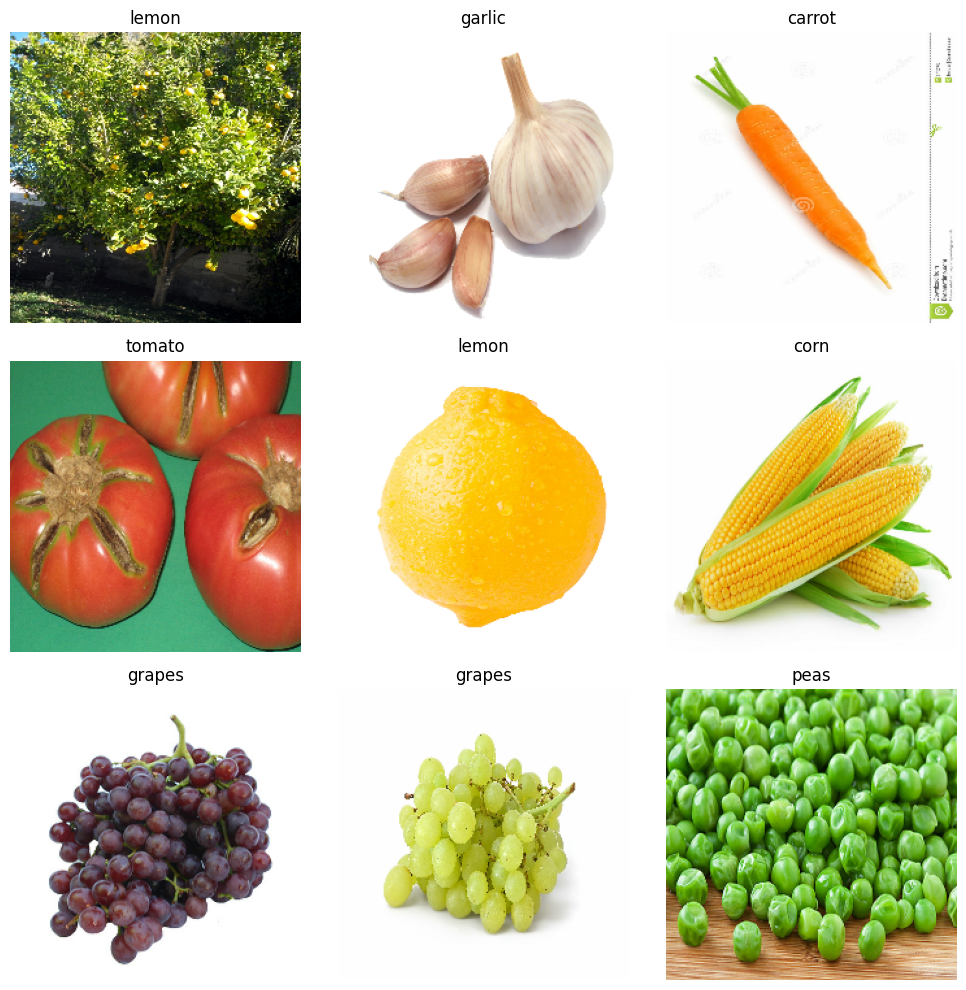

In [ ]:
# Sample images
plt.figure(figsize=(10, 10))
for i, idx in enumerate(np.random.RandomState(SEED).choice(len(p_train), 9, replace=False)):
    img, lab = load_image(p_train[idx], y_train[idx])
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(class_names[lab])
    plt.axis("off")
plt.tight_layout()
plt.show()

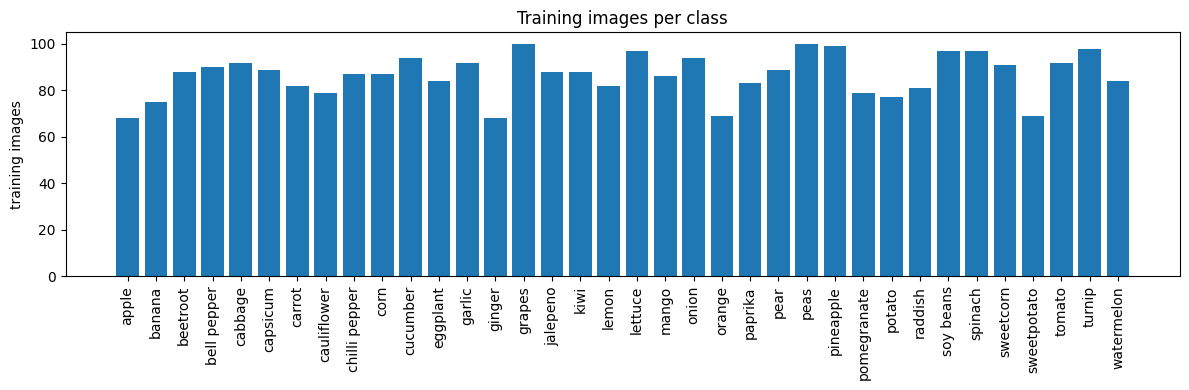

In [ ]:
# Images per class in the training set (check that the classes are balanced)
counts = np.bincount(y_train, minlength=NUM_CLASSES)
plt.figure(figsize=(12, 4))
plt.bar(range(NUM_CLASSES), counts)
plt.xticks(range(NUM_CLASSES), class_names, rotation=90)
plt.ylabel("training images")
plt.title("Training images per class")
plt.tight_layout()
plt.show()

## 5. Data augmentation

Augmentation creates slightly different versions of each image during training (flipped, rotated, shifted, zoomed, brighter or darker). This helps the model cope with real phone photos, which are never as clean as the training photos. It is only active during training.

In [ ]:
augment = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.12),
        layers.RandomZoom((-0.25, 0.1)),
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ],
    name="augmentation",
)

## 6. CNN architecture

### Model A: baseline CNN from scratch
Four convolution blocks. Each block is **Conv2D > BatchNormalization > ReLU > MaxPooling**. The filters grow (32, 64, 128, 256) so early layers learn simple edges and later layers learn shapes and textures. **GlobalAveragePooling** turns the feature maps into one vector, **Dropout** reduces overfitting, and a **softmax** layer gives one probability per food class. It is kept as the "before" in your comparison table.

In [ ]:
def build_baseline():
    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
    x = augment(inputs)
    x = layers.Rescaling(1.0 / 255)(x)          # pixel values 0-255 -> 0-1
    for filters in (32, 64, 128, 256):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="food_class")(x)   # float32 output also under mixed precision
    return keras.Model(inputs, outputs, name="baseline_cnn")


baseline = build_baseline()
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ food_class (Dense)              │ (None, 36)             │         9,252 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 399,108 (1.52 MB)

 Trainable params: 398,148 (1.52 MB)

 Non-trainable params: 960 (3.75 KB)

### Model B: transfer learning with EfficientNet (main model)

EfficientNet was already trained on millions of ImageNet photos, so it knows general shapes, colours and textures. It scales depth, width and resolution together, which is why it beats MobileNetV2 at a similar cost. The recipe:

1. **Stage 1:** keep EfficientNet frozen and train only the new classification head.
2. **Stage 2:** unfreeze the top `FINETUNE_FRACTION` of EfficientNet and train it with a small learning rate. **BatchNorm layers stay frozen**, which is the usual fix for fine-tuning instabilities on small datasets.
3. **Label smoothing, class weights and mixed precision** are switched on in the settings.

EfficientNet has its own input scaling built in, so the images are passed in as 0 to 255 values. (MobileNetV2, if you choose it for comparison, gets its own rescaling layer below.)

In [ ]:
BACKBONES = {
    "EfficientNetV2B0": keras.applications.EfficientNetV2B0,
    "EfficientNetB0": keras.applications.EfficientNetB0,
    "EfficientNetV2S": keras.applications.EfficientNetV2S,
    "MobileNetV2": keras.applications.MobileNetV2,
}


def build_transfer(model_name=None):
    model_name = model_name or MODEL_NAME
    base = BACKBONES[model_name](input_shape=IMG_SIZE + (3,), include_top=False, weights=WEIGHTS)
    base.trainable = False                       # frozen for the first training stage

    inputs = keras.Input(shape=IMG_SIZE + (3,), name="image")
    x = augment(inputs)
    if model_name == "MobileNetV2":              # EfficientNet rescales inside the model, MobileNetV2 does not
        x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
    x = base(x, training=False)                  # training=False keeps BatchNorm in inference mode, also later when unfrozen
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32", name="food_class")(x)
    return keras.Model(inputs, outputs, name=f"{model_name.lower()}_transfer"), base


transfer, base_model = build_transfer()
print("Backbone:", MODEL_NAME, "| layers:", len(base_model.layers), "| parameters:", f"{transfer.count_params():,}")
transfer.summary()

24274472/24274472 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Backbone: EfficientNetV2B0 | layers: 270 | parameters: 5,970,548


Model: "efficientnetv2b0_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b0 (Functional)  │ (None, 7, 7, 1280)     │     5,919,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ food_class (Dense)              │ (None, 36)             │        46,116 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,970,548 (22.78 MB)

 Trainable params: 48,676 (190.14 KB)

 Non-trainable params: 5,921,872 (22.59 MB)

## 7. Train

In [ ]:
def compile_model(model, lr):
    model.compile(
        optimizer=keras.optimizers.Adam(lr),
        loss=keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING),
        metrics=[
            keras.metrics.CategoricalAccuracy(name="accuracy"),
            keras.metrics.TopKCategoricalAccuracy(k=min(3, NUM_CLASSES), name="top3"),
        ],
    )


def make_callbacks(name):
    return [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(f"{name}.keras", monitor="val_accuracy", save_best_only=True),
    ]


def unfreeze_top(base, fraction):
    """Unfreeze the top `fraction` of the backbone but keep every BatchNorm layer frozen."""
    base.trainable = True
    cut = int(len(base.layers) * (1 - fraction))
    for i, layer in enumerate(base.layers):
        layer.trainable = i >= cut and not isinstance(layer, layers.BatchNormalization)
    print(f"Unfrozen: {sum(l.trainable for l in base.layers)} of {len(base.layers)} backbone layers (BatchNorm stays frozen)")


def plot_history(histories, title):
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in histories:
        acc += h.history["accuracy"]; val_acc += h.history["val_accuracy"]
        loss += h.history["loss"]; val_loss += h.history["val_loss"]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(acc, label="train"); ax[0].plot(val_acc, label="validation")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(loss, label="train"); ax[1].plot(val_loss, label="validation")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

Epoch 1/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 85s 718ms/step - accuracy: 0.1233 - loss: 3.3322 - top3: 0.3082 - val_accuracy: 0.0456 - val_loss: 3.6430 - val_top3: 0.1282 - learning_rate: 0.0010
Epoch 2/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 70s 711ms/step - accuracy: 0.1872 - loss: 2.9863 - top3: 0.4263 - val_accuracy: 0.0655 - val_loss: 3.7673 - val_top3: 0.1425 - learning_rate: 0.0010
Epoch 3/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 68s 682ms/step - accuracy: 0.2241 - loss: 2.8670 - top3: 0.4783 - val_accuracy: 0.1054 - val_loss: 3.7877 - val_top3: 0.1909 - learning_rate: 0.0010
Epoch 4/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 69s 698ms/step - accuracy: 0.2613 - loss: 2.7799 - top3: 0.5246 - val_accuracy: 0.1624 - val_loss: 2.8396 - val_top3: 0.4473 - learning_rate: 3.0000e-04
Epoch 5/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 705ms/step - accuracy: 0.2681 - loss: 2.7478 - top3: 0.5422 - val_accuracy: 0.3447 - val_loss: 2.5470 - val_top3: 0.6040 - learning_rate: 3.0000e-04
Epoch 6/20
98/98 ━━━━━━━━━━━━━━━━━━━━ 69s 709ms/step - ac

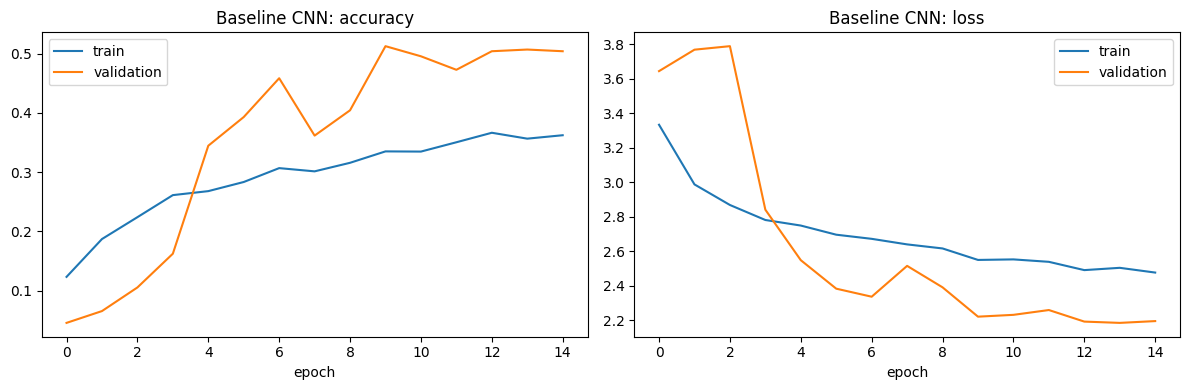

In [ ]:
# Train Model A (baseline CNN). Switch it off with TRAIN_BASELINE = False if you only need the EfficientNet result.
if TRAIN_BASELINE:
    compile_model(baseline, 1e-3)
    hist_base = baseline.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
        class_weight=CLASS_WEIGHT, callbacks=make_callbacks("baseline_cnn"),
    )
    plot_history([hist_base], "Baseline CNN")

In [ ]:
# Train Model B, stage 1: backbone frozen, only the new head learns
compile_model(transfer, 1e-3)
hist_t1 = transfer.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_TRANSFER,
    class_weight=CLASS_WEIGHT, callbacks=make_callbacks("effnet_stage1"),
)

Epoch 1/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 88s 711ms/step - accuracy: 0.4347 - loss: 2.4857 - top3: 0.6600 - val_accuracy: 0.8034 - val_loss: 1.5475 - val_top3: 0.9687 - learning_rate: 0.0010
Epoch 2/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 67s 678ms/step - accuracy: 0.6979 - loss: 1.6269 - top3: 0.8934 - val_accuracy: 0.8547 - val_loss: 1.1555 - val_top3: 0.9715 - learning_rate: 0.0010
Epoch 3/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 82s 682ms/step - accuracy: 0.7518 - loss: 1.4575 - top3: 0.9252 - val_accuracy: 0.8575 - val_loss: 1.0917 - val_top3: 0.9772 - learning_rate: 0.0010
Epoch 4/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 67s 682ms/step - accuracy: 0.7820 - loss: 1.3715 - top3: 0.9461 - val_accuracy: 0.8689 - val_loss: 1.0886 - val_top3: 0.9772 - learning_rate: 0.0010
Epoch 5/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 73s 740ms/step - accuracy: 0.7978 - loss: 1.3161 - top3: 0.9509 - val_accuracy: 0.9031 - val_loss: 1.0622 - val_top3: 0.9829 - learning_rate: 0.0010
Epoch 6/8
98/98 ━━━━━━━━━━━━━━━━━━━━ 67s 681ms/step - accuracy: 0.8141

Unfrozen: 86 of 270 backbone layers (BatchNorm stays frozen)
Epoch 1/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 93s 733ms/step - accuracy: 0.9066 - loss: 1.0373 - top3: 0.9894 - val_accuracy: 0.9402 - val_loss: 0.9327 - val_top3: 0.9915 - learning_rate: 1.0000e-04
Epoch 2/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 69s 709ms/step - accuracy: 0.9178 - loss: 1.0140 - top3: 0.9917 - val_accuracy: 0.9430 - val_loss: 0.9412 - val_top3: 0.9915 - learning_rate: 1.0000e-04
Epoch 3/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 78s 792ms/step - accuracy: 0.9236 - loss: 1.0024 - top3: 0.9929 - val_accuracy: 0.9516 - val_loss: 0.9252 - val_top3: 0.9915 - learning_rate: 1.0000e-04
Epoch 4/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 73s 703ms/step - accuracy: 0.9390 - loss: 0.9799 - top3: 0.9971 - val_accuracy: 0.9516 - val_loss: 0.8989 - val_top3: 0.9915 - learning_rate: 1.0000e-04
Epoch 5/25
98/98 ━━━━━━━━━━━━━━━━━━━━ 69s 705ms/step - accuracy: 0.9371 - loss: 0.9654 - top3: 0.9949 - val_accuracy: 0.9601 - val_loss: 0.9043 - val_top3: 0.9915 - learning_r

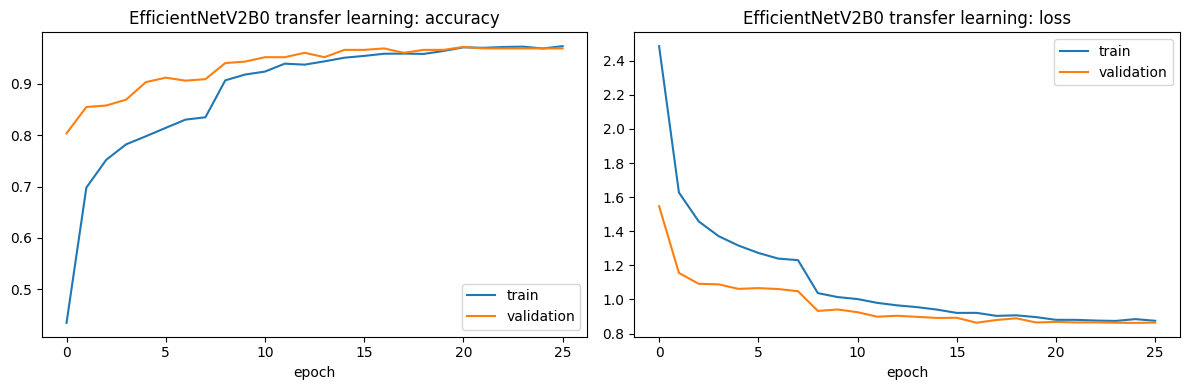

In [ ]:
# Train Model B, stage 2: fine-tune the top of the backbone with a small learning rate (BatchNorm stays frozen)
unfreeze_top(base_model, FINETUNE_FRACTION)
compile_model(transfer, 1e-4)          # the model must be compiled again after changing what is trainable
hist_t2 = transfer.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE,
    class_weight=CLASS_WEIGHT, callbacks=make_callbacks("effnet_finetuned"),
)
plot_history([hist_t1, hist_t2], f"{MODEL_NAME} transfer learning")

## 8. Evaluate on the test set

The test set was never used during training, and because duplicates were removed **before** splitting, no near-copy of a test image sits in the training set. So these numbers show how the model does on genuinely new images. We report **top-1 accuracy**, **top-3 accuracy**, **precision / recall / F1** for each class, and a **confusion matrix** (which foods get mixed up). With `USE_TTA = True` each photo is also tested mirrored and the two predictions are averaged, which usually adds a little accuracy for free.

In [ ]:
def predict_probs(model, ds, tta=False):
    probs = model.predict(ds, verbose=0)
    if tta:
        flipped = ds.map(lambda x, y: (tf.image.flip_left_right(x), y))
        probs = (probs + model.predict(flipped, verbose=0)) / 2.0
    return probs


def evaluate(model, name, tta=False):
    probs = predict_probs(model, test_ds, tta=tta)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_pred = probs.argmax(axis=1)
    top1 = float((y_pred == y_true).mean())
    k = min(3, NUM_CLASSES)
    top3 = float(np.mean([t in np.argsort(p)[-k:] for t, p in zip(y_true, probs)]))
    print(f"{name}: top-1 accuracy = {top1:.3f}   top-3 accuracy = {top3:.3f}")
    return y_true, y_pred, top1, top3, probs


if TRAIN_BASELINE:
    yt_b, yp_b, top1_b, top3_b, _ = evaluate(baseline, "Baseline CNN")
yt_t, yp_t, top1_t, top3_t, probs_t = evaluate(transfer, f"{MODEL_NAME} (fine-tuned)")
if USE_TTA:
    yt_t, yp_t, top1_t, top3_t, probs_t = evaluate(transfer, f"{MODEL_NAME} (fine-tuned) + flip TTA", tta=True)

Baseline CNN: top-1 accuracy = 0.507   top-3 accuracy = 0.758
EfficientNetV2B0 (fine-tuned): top-1 accuracy = 0.972   top-3 accuracy = 0.986
EfficientNetV2B0 (fine-tuned) + flip TTA: top-1 accuracy = 0.975   top-3 accuracy = 0.986


In [ ]:
# Comparison table
label = f"{MODEL_NAME} (fine-tuned)" + (" + TTA" if USE_TTA else "")
print(f"{'Model':36s} {'Top-1':>8s} {'Top-3':>8s}")
if TRAIN_BASELINE:
    print(f"{'Baseline CNN':36s} {top1_b:8.3f} {top3_b:8.3f}")
print(f"{label:36s} {top1_t:8.3f} {top3_t:8.3f}")
print("\nProposed targets: top-1 >= 0.85 and top-3 >= 0.95 (agree these with your mentor).")

Model                                   Top-1    Top-3
Baseline CNN                            0.507    0.758
EfficientNetV2B0 (fine-tuned) + TTA     0.975    0.986

Proposed targets: top-1 >= 0.85 and top-3 >= 0.95 (agree these with your mentor).


In [ ]:
# Precision, recall and F1 for each class (EfficientNet model)
print(classification_report(yt_t, yp_t, labels=range(NUM_CLASSES), target_names=class_names, zero_division=0))

               precision    recall  f1-score   support

        apple       0.90      0.90      0.90        10
       banana       1.00      0.89      0.94         9
     beetroot       1.00      1.00      1.00        10
  bell pepper       1.00      0.90      0.95        10
      cabbage       1.00      1.00      1.00        10
     capsicum       0.77      1.00      0.87        10
       carrot       1.00      0.90      0.95        10
  cauliflower       1.00      1.00      1.00        10
chilli pepper       1.00      1.00      1.00        10
         corn       0.82      0.90      0.86        10
     cucumber       1.00      1.00      1.00        10
     eggplant       1.00      1.00      1.00        10
       garlic       1.00      1.00      1.00        10
       ginger       1.00      1.00      1.00        10
       grapes       1.00      1.00      1.00        10
     jalepeno       1.00      1.00      1.00        10
         kiwi       1.00      1.00      1.00        10
        l

In [ ]:
# How good is the model when it is sure? Predictions below CONFIDENCE_THRESHOLD are sent to the user to confirm.
conf = probs_t.max(axis=1)
sure = conf >= CONFIDENCE_THRESHOLD
print(f"Threshold {CONFIDENCE_THRESHOLD:.2f}: the app answers on {sure.mean():.1%} of photos, and is right on {(yp_t[sure] == yt_t[sure]).mean():.1%} of those.")
print(f"The other {(~sure).mean():.1%} of photos would show 'not sure, please confirm' with the top-3 guesses.")
for t in (0.3, 0.5, 0.7, 0.9):
    m = conf >= t
    print(f"   threshold {t:.1f}: answers {m.mean():6.1%}   accuracy when answering {(yp_t[m] == yt_t[m]).mean() if m.any() else float('nan'):6.1%}")

Threshold 0.50: the app answers on 97.5% of photos, and is right on 98.6% of those.
The other 2.5% of photos would show 'not sure, please confirm' with the top-3 guesses.
   threshold 0.3: answers  99.4%   accuracy when answering  97.8%
   threshold 0.5: answers  97.5%   accuracy when answering  98.6%
   threshold 0.7: answers  92.8%   accuracy when answering  99.7%
   threshold 0.9: answers  76.0%   accuracy when answering 100.0%


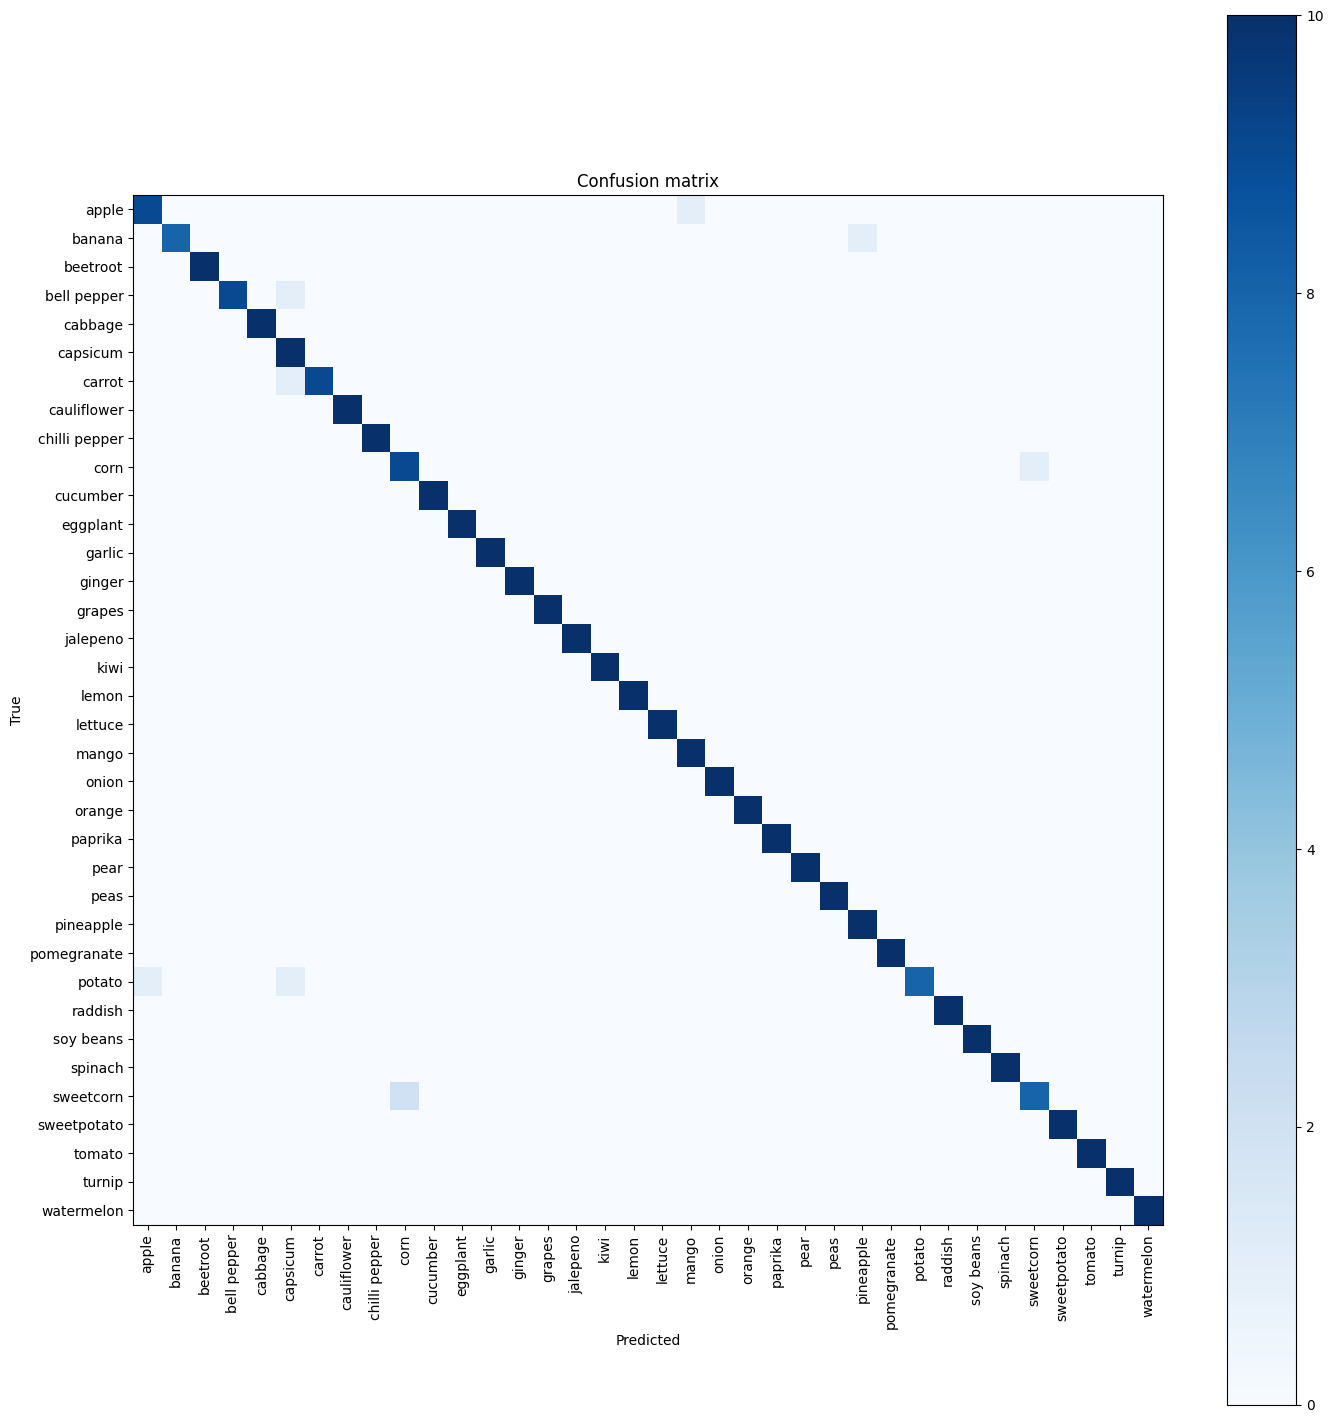

In [ ]:
# Confusion matrix (transfer-learning model)
cm = confusion_matrix(yt_t, yp_t, labels=range(NUM_CLASSES))
size = min(40, max(6, NUM_CLASSES * 0.4))
fig, ax = plt.subplots(figsize=(size, size))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix")
fig.colorbar(im)
plt.tight_layout(); plt.show()

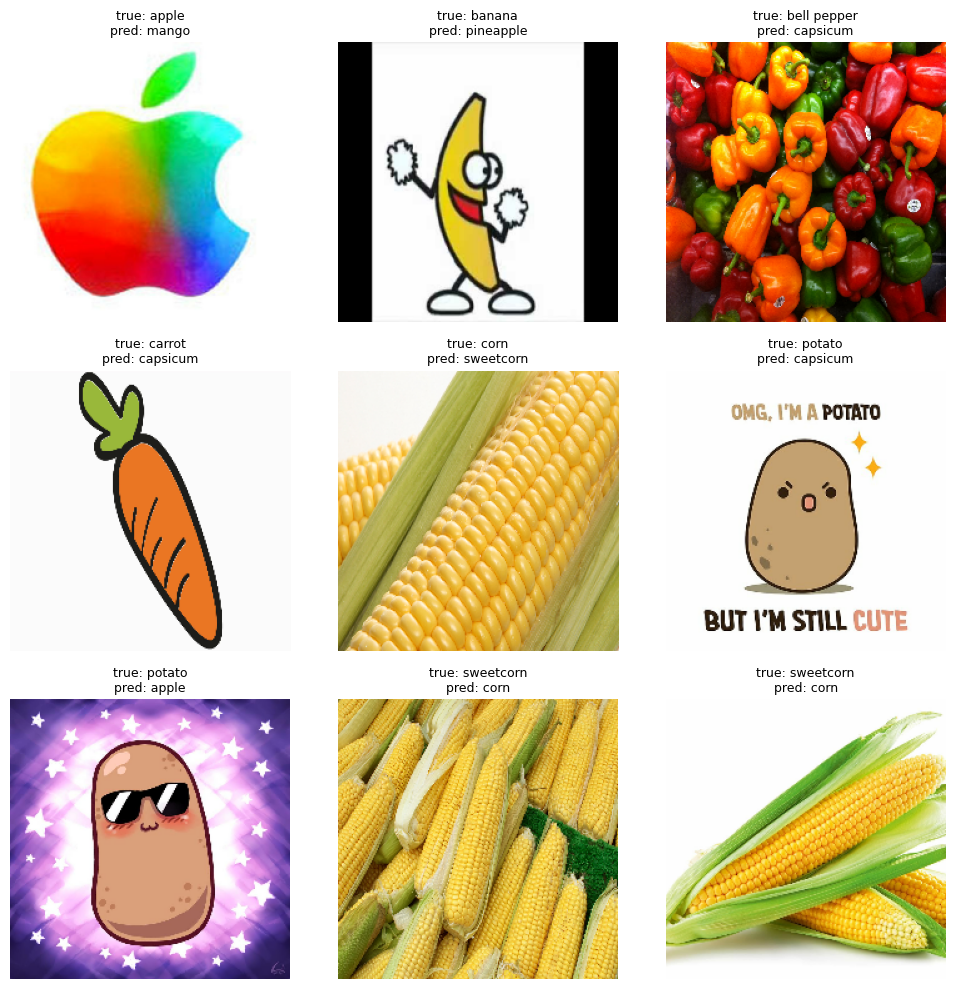

In [ ]:
# Examples the model got wrong (useful for your failure-case section in the report)
wrong = np.where(yt_t != yp_t)[0][:9]
plt.figure(figsize=(10, 10))
for i, idx in enumerate(wrong):
    img, _ = load_image(p_test[idx], y_test[idx])
    plt.subplot(3, 3, i + 1)
    plt.imshow(img.numpy().astype("uint8"))
    plt.title(f"true: {class_names[yt_t[idx]]}\npred: {class_names[yp_t[idx]]}", fontsize=9)
    plt.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Optional but important: test on YOUR OWN phone photos, kept completely out of training.
# Put them in /content/own_test/<item>/photo.jpg (same item names as the class folders).
OWN_TEST_DIR = "/content/own_test"
if os.path.isdir(OWN_TEST_DIR) and any(os.scandir(OWN_TEST_DIR)):
    names_own = [c for c in sorted(os.listdir(OWN_TEST_DIR)) if c in class_names]
    _, p_own, y_own_names = list_images(OWN_TEST_DIR, names_own)
    y_own = np.array([class_names.index(names_own[i]) for i in y_own_names])
    own_ds = make_ds(p_own, y_own, training=False, onehot=False)
    pr = predict_probs(transfer, own_ds, tta=USE_TTA)
    yp = pr.argmax(axis=1)
    top3_own = np.mean([t in np.argsort(p)[-3:] for t, p in zip(y_own, pr)])
    print(f"Own phone photos: {len(p_own)} images, top-1 = {(yp == y_own).mean():.3f}, top-3 = {top3_own:.3f}")
    print("Report this number separately in your evaluation report. It is the honest real-world result.")
else:
    print("No own-photo test set found at", OWN_TEST_DIR, "- add one before you report final accuracy.")

No own-photo test set found at /content/own_test - add one before you report final accuracy.


## 9. Try it on your own photo

Take a photo of a food item on your phone, upload it, and see the top 3 guesses. If the best guess is below `CONFIDENCE_THRESHOLD` the notebook says it is not sure. This is the behaviour the web app should copy: show the top-3, let the user correct the label, and save corrected photos for the next training round. **Real phone photos are the most important test** of your project.

Saving 93-Apple-raw.jpeg to 93-Apple-raw.jpeg


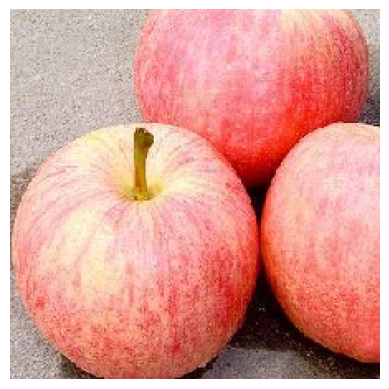

apple                   92.5%
pomegranate              2.8%
garlic                   0.5%


In [ ]:
# [COLAB] Upload a photo and predict
from google.colab import files
up = files.upload()
for fn in up:
    img = keras.utils.load_img(fn, target_size=IMG_SIZE)
    x = keras.utils.img_to_array(img)[None, ...]               # 0-255 values: EfficientNet rescales inside the model
    probs = (transfer.predict(x, verbose=0)[0] + transfer.predict(x[:, :, ::-1, :], verbose=0)[0]) / 2   # photo + mirror image
    top = np.argsort(probs)[::-1][:3]
    plt.imshow(img); plt.axis("off"); plt.show()
    if probs[top[0]] < CONFIDENCE_THRESHOLD:
        print("Not sure. Please confirm one of these:")
    for i in top:
        print(f"{class_names[i]:22s} {probs[i] * 100:5.1f}%")

## 10. Save the model

The saved model and the class list are what your web app (Flask or FastAPI) will load later.

In [ ]:
transfer.save("food_cnn_effnet.keras")
with open("class_names.json", "w") as f:
    json.dump(class_names, f)
# model_card.json: what the web app and your report need to know about this model
card = dict(model=MODEL_NAME, img_size=list(IMG_SIZE), num_classes=NUM_CLASSES, preprocessing="pass 0-255 pixel values (rescaling is inside the model)" if MODEL_NAME != "MobileNetV2" else "pass 0-255 pixel values",
            top1_test=round(top1_t, 4), top3_test=round(top3_t, 4), confidence_threshold=CONFIDENCE_THRESHOLD, tta=USE_TTA,
            label_smoothing=LABEL_SMOOTHING, trained_on_images=int(len(p_train)), seed=SEED)
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=2)
print("Saved: food_cnn_effnet.keras, class_names.json, model_card.json")

Saved: food_cnn_effnet.keras, class_names.json, model_card.json


In [ ]:
# [COLAB] Copy the files to Google Drive so you keep them after the session ends
from google.colab import drive
import shutil
drive.mount("/content/drive")
os.makedirs("/content/drive/MyDrive/food_cnn_outputs", exist_ok=True)
for fn in ["food_cnn_effnet.keras", "class_names.json", "model_card.json", "baseline_cnn.keras", "food_cnn.tflite",
           "/content/class_to_category.csv", "/content/space_report.csv"]:
    if os.path.exists(fn):
        shutil.copy(fn, "/content/drive/MyDrive/food_cnn_outputs/")
print("Copied to Drive: food_cnn_outputs")
# The cleaned dataset is small now (images are stored shrunk). Saving it means you never rebuild it:
#   !cd /content && zip -qr data.zip data && cp data.zip /content/drive/MyDrive/food_cnn_outputs/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to Drive: food_cnn_outputs


In [ ]:
# Optional: convert to TensorFlow Lite for a future mobile app
try:
    keras.mixed_precision.set_global_policy("float32")     # export a clean float32 graph
    export_model, _ = build_transfer()
    export_model.set_weights(transfer.get_weights())
    converter = tf.lite.TFLiteConverter.from_keras_model(export_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()
    with open("food_cnn.tflite", "wb") as f:
        f.write(tflite_model)
    print("TFLite size (MB):", round(len(tflite_model) / 1e6, 2))
except Exception as e:
    print("TFLite export failed (the .keras file is still fine for a web app):", e)

Saved artifact at '/tmp/tmpwo0x2cc5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='image')
Output Type:
  TensorSpec(shape=(None, 36), dtype=tf.float32, name=None)
Captures:
  136285393191568: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136285395174032: TensorSpec(shape=(1, 1, 1, 3), dtype=tf.float32, name=None)
  136285405227024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392158160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392146064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285393191760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392157968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392145872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392150480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136285392157584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13

## Next steps (end-to-end plan)

**Data**
1. Add your own phone photos (100 to 200 per item, especially Indian items and the MISSING ones) to `/content/data/<item>/`, then run the clean-up cell again.
2. Keep a test set made only of your own phone photos in `/content/own_test/` and report its accuracy separately.
3. Keep `class_to_category.csv`, `space_report.csv` and the source list as the dataset document, with each licence.

**Model**
4. Run the comparison: baseline CNN, `MODEL_NAME = "MobileNetV2"`, and `"EfficientNetV2B0"`. Same data, same split, same seed. Put the table in the report.
5. If accuracy is still short: raise `MAX_PER_CLASS`, add more real photos for the weakest classes (see the per-class F1 table), try `EfficientNetV2S` at 300 px, or train 2 to 3 seeds and average them.

**Packaged products and milk**
6. The classifier recognises a product *type* (milk, curd, oil). For brand and nutrition, add a **barcode scan** step and look the product up in Open Food Facts.

**App**
7. Serve `food_cnn_effnet.keras` with FastAPI (`/predict` returns top-3 and confidence). Below `CONFIDENCE_THRESHOLD` show "not sure, please confirm".
8. Link each class to a nutrition row (USDA FoodData Central or the Indian Food Composition Tables) and rank recipes by how many recognised items they use.
9. Save every user correction with its photo. That is your next training round.
